# What should we do about FTIR EC where the IMPROVE calibration does not transfer? (22 Oct 2026)

SPARTAN reports **FTIR EC** (elemental carbon from the filter's infrared spectrum) from a **PLS** calibration trained on
**IMPROVE** filters (rural US network) against their **TOR** EC (thermal-optical reflectance, a combustion measurement).
At Addis Ababa that calibration disagrees with **HIPS** light absorption (HIPS BC = Fabs ÷ **MAC** 10 m²/g), while the
network as a whole agrees. This workbook lays out the options and tests each with the data we already have.

| Option | The idea | Tested here by |
|---|---|---|
| **A. One better model** | A single calibration (preprocessing, number of PLS components k, or a local calibration per filter) that also works on the hard filters | Sections 7 and 7b |
| **B. Several models and a rule to pick one** | Specialist calibrations (heavy loading, low OC/BC, smoke, urban, Addis-like spectra, or each filter's own analogs) chosen per filter, site or season | Section 4 |
| **C. A flag for filters the calibration cannot be trusted on** | Detect, from each filter's own spectrum (and its HIPS), when FTIR EC is likely wrong; report which sites and seasons are affected | Sections 5, 6 and 6b |
| **D. New reference data** | The ~10 Addis TOR filters expected, later a collocated campaign | Section 8 (what they must show, written down before they arrive) |

**What can be judged with what.** Only IMPROVE has an independent EC truth (TOR), so every fair test of A, B and C is
run inside IMPROVE, holding out whole sites. SPARTAN has HIPS only, and HIPS ÷ 10 is itself an assumption (the MAC), so
network results are a cross-check, never the verdict. (SPARTAN's ChemSpec EC is the FTIR value itself.)

**How to use.** Run top to bottom (Runtime → Run all). With the default settings it took 8.5 minutes on a 10-core Mac;
a free Colab CPU VM has 2 cores, so expect about 40 minutes, almost all of it Section 4. For a quick first pass set
`N_REPEATS = 4` and `LOCAL_PER_GROUP = 20` in the settings cell (about 10 minutes). Every table is also
saved to `results/<date-time>/` next to the data on Drive.

**Words used below.** *Calibration set*: the IMPROVE filters a PLS model is fitted to. *Out-of-site prediction*: the
prediction for a filter from a model that never saw any filter from its site. *k*: number of PLS components. *µg per
filter*: mass on the filter (concentration × sampled air volume); IMPROVE samples about 33 m³ per filter, SPARTAN about
7 m³, so per filter is the fair comparison. *HIPS µg per filter*: Fabs ÷ 10 × volume.

In [1]:
# 0. Where the data is: Colab mounts Drive and copies the bundle to the VM; locally it reads the Drive folder
import os, sys, json, time, shutil
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
DRIVE_FOLDER = "Aethmodular VIBES/decision_workbook_20261022"
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    HOME = Path("/content/drive/MyDrive") / DRIVE_FOLDER
    BUNDLE = Path("/content/bundle")            # a copy on the VM reads far faster than the Drive mount
    if not (BUNDLE / "MANIFEST.json").exists():
        t0 = time.time()
        shutil.copytree(HOME / "bundle", BUNDLE, dirs_exist_ok=True)
        print(f"copied the bundle to the VM in {time.time() - t0:.0f} s")
else:
    HOME = Path(os.environ.get("DECISION_HOME") or
                next(Path.home().glob("Library/CloudStorage/GoogleDrive-*/My Drive")) / DRIVE_FOLDER)
    BUNDLE = HOME / "bundle"
RESULTS = HOME / "results" / time.strftime("%Y%m%d-%H%M")
MANIFEST = json.loads((BUNDLE / "MANIFEST.json").read_text())
print(f"bundle built {MANIFEST['created']} · {len(MANIFEST['files'])} files · results go to {RESULTS}")

bundle built 2026-10-22 · 18 files · results go to /Users/ahmadjalil/Library/CloudStorage/GoogleDrive-ahzs645@gmail.com/My Drive/Aethmodular VIBES/decision_workbook_20261022/results/20261026-1442


In [2]:
# Settings (the only cell to edit)
PREPS_ALL = ["spline", "raw", "vibes"]   # Sections 2 and 7 compare every preprocessing
PREPS = ["spline", "raw"]                # Section 4: the current default (spline) and what SPARTAN deploys (raw)
MAIN = "spline"                          # the preprocessing the flag in Sections 5-6 is built on
K_MAX = 25                               # PLS components tried
N_FOLDS = 5                              # site-grouped folds for out-of-site predictions
N_REPEATS = 10                           # Section 4 site splits (each about 20-40 s on Colab)
TRAIN_SHARE = 0.7                        # share of IMPROVE sites used for training in each split
N_SELECT = 500                           # IMPROVE filters per specialist calibration (the size used all year)
GROUP_PCT = 5                            # a hard group is the most extreme 5 % of IMPROVE on its variable
LOCAL_PER_GROUP = 40                     # per-filter local models per group and split (0 skips them)
ABS_TOL, REL_TOL = 2.0, 0.50             # "impacted": |FTIR - TOR| > 2 µg per filter AND > half of TOR (about 1 IMPROVE filter in 5)
FLAG_AT = 0.5                            # a filter is flagged when its predicted chance of being impacted is >= this
MAC = 10.0
LAMBDA_ADDIS = (0.531 / (2.9075 / MAC)) ** 2   # Deming error ratio of every Addis panel (sigma_x from HIPS uncertainty)
SEED = 20261022

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, roc_auc_score

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
RESULTS.mkdir(parents=True, exist_ok=True)

WN = {"raw": np.load(BUNDLE / "wn_full.npy").astype(float), "spline": np.load(BUNDLE / "wn_spline.npy").astype(float)}
WN["vibes"] = WN["raw"]
spectra = lambda pop, prep: np.load(BUNDLE / f"{pop}_{prep}.npy").astype(float)

im = pd.read_csv(BUNDLE / "improve_meta.csv", parse_dates=["date"])
am = pd.read_csv(BUNDLE / "addis_meta.csv", parse_dates=["date"])
nm = pd.read_csv(BUNDLE / "network_meta.csv", parse_dates=["date"])
seasons = pd.read_csv(BUNDLE / "site_seasons.csv")
SITE_NAME = seasons.drop_duplicates("code").set_index("code").site_name.to_dict()

# One IMPROVE filter (TONT1 2022-11-19) has a corrupt raw spectrum; it leaves every comparison, not only the raw ones
keep = im.raw_qc_ok.to_numpy()
im = im[keep].reset_index(drop=True)
XI = {p: spectra("improve", p)[keep] for p in PREPS_ALL}
XA = {p: spectra("addis", p) for p in PREPS_ALL}
XN = {p: spectra("network", p) for p in PREPS_ALL}

# per-filter quantities every population has
im["hips_ug"] = im.fabs_Mm1 / MAC * im.volume_m3
im["oc_bc"] = im.tor_oc_ugm3 / (im.fabs_Mm1.clip(lower=0.05) / MAC)       # TOR OC over HIPS BC, as Addis is measured
nm["hips_bc"] = nm.fabs_Mm1 / MAC
nm["hips_ug"] = nm.hips_bc * nm.volume_m3
nm["oc_bc"] = nm.oc_ftir_ugm3 / nm.hips_bc.clip(lower=0.005)
nm["month"] = nm.date.dt.month
nm = nm.merge(seasons[["code", "month", "season"]], on=["code", "month"], how="left")
am = am.merge(nm[["filter_id", "oc_ftir_ugm3", "pm25_ugm3"]], on="filter_id", how="left")
am["hips_bc"] = am.fabs_Mm1 / MAC
am["hips_ug"] = am.hips_bc * am.volume_m3
am["oc_bc"] = am.oc_ftir_ugm3 / am.hips_bc
ADDIS = ~am.excluded.to_numpy()

y = im.ec_ug.to_numpy()          # TOR EC per filter: what every IMPROVE model is fitted to and judged against
sites = im.site.to_numpy()
print(f"IMPROVE {len(im):,} filters at {im.site.nunique()} sites · Addis {ADDIS.sum()} of {len(am)} · "
      f"SPARTAN network {len(nm):,} filters at {nm.code.nunique()} sites")

IMPROVE 12,392 filters at 157 sites · Addis 233 of 233 · SPARTAN network 3,517 filters at 28 sites


### Toolbox
A fast PLS1 (NIPALS without deflating the spectra, so one fit gives every first-k model and the score distance T² and
spectral residual Q of any filter), site-grouped folds with the one-standard-error choice of k, the fit readouts, and the
band features used by the flag. The next cell checks the PLS against scikit-learn.

In [4]:
class PLS:
    """PLS1 regression. One fit at kmax gives the first-k model for every k <= kmax."""
    def __init__(self, kmax=K_MAX):
        self.kmax = kmax

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        self.xm, self.ym = X.mean(0), y.mean()
        Xc, f = X - self.xm, y - self.ym
        n, p = Xc.shape
        K = int(min(self.kmax, n - 2, p))
        W, P, T, q = np.zeros((p, K)), np.zeros((p, K)), np.zeros((n, K)), np.zeros(K)
        x2 = np.einsum("ij,ij->i", Xc, Xc)
        cross, quad, qmed = np.zeros(n), np.zeros(n), np.zeros(K)
        for a in range(K):
            w = Xc.T @ f
            w /= np.linalg.norm(w)
            t = Xc @ w - T[:, :a] @ (P[:, :a].T @ w)
            if a:
                t -= T[:, :a] @ ((T[:, :a].T @ t) / (T[:, :a] ** 2).sum(0))     # keep the scores orthogonal
            tt = t @ t
            pa, qa = Xc.T @ t / tt, f @ t / tt
            f = f - qa * t
            quad += t * t * (pa @ pa) + 2 * t * (T[:, :a] @ (P[:, :a].T @ pa))
            cross += t * (Xc @ pa)
            W[:, a], P[:, a], T[:, a], q[a] = w, pa, t, qa
            qmed[a] = np.median(x2 - 2 * cross + quad)                      # training spectral residual Q
        self.W, self.P, self.q, self.K, self.qmed = W, P, q, K, qmed
        self.tvar = (T ** 2).sum(0) / (n - 1)
        self.B = np.column_stack([self.R(k) @ q[:k] for k in range(1, K + 1)])
        return self

    def R(self, k):
        return self.W[:, :k] @ np.linalg.inv(self.P[:, :k].T @ self.W[:, :k])

    def predict(self, X):
        """(n, K): column k-1 is the k-component prediction."""
        return (np.asarray(X, float) - self.xm) @ self.B + self.ym

    def distances(self, X, k):
        """Score distance (Hotelling T² per component) and spectral residual Q / training median Q, at k components."""
        Xc = np.asarray(X, float) - self.xm
        T, Pk = Xc @ self.R(k), self.P[:, :k]
        t2 = (T ** 2 / self.tvar[:k]).sum(1) / k
        Q = np.einsum("ij,ij->i", Xc, Xc) - 2 * (T * (Xc @ Pk)).sum(1) + ((T @ (Pk.T @ Pk)) * T).sum(1)
        return t2, Q / self.qmed[k - 1]


def site_folds(site_arr, n_folds, rng):
    u = np.unique(site_arr)
    rng.shuffle(u)
    n_folds = min(n_folds, len(u))
    lab = {s: i % n_folds for i, s in enumerate(u)}
    return np.array([lab[s] for s in site_arr]), n_folds


def one_se(err):
    """Smallest k whose mean CV RMSE is within one standard error of the best (err: folds x k)."""
    m = np.nanmean(err, 0)
    se = np.nanstd(err, 0, ddof=1) / np.sqrt(np.isfinite(err).sum(0))
    b = int(np.nanargmin(m))
    return int(np.flatnonzero(m <= m[b] + se[b])[0]) + 1


def cv_k(X, yy, site_arr, rng, n_folds=3, kmax=K_MAX):
    """k for a calibration set, by site-grouped CV inside it (never looks at the target)."""
    folds, nf = site_folds(site_arr, n_folds, rng)
    if nf < 2:
        return min(5, kmax)
    err = np.full((nf, kmax), np.nan)
    for f in range(nf):
        tr = folds != f
        m = PLS(kmax).fit(X[tr], yy[tr])
        err[f, :m.K] = np.sqrt(((m.predict(X[~tr]) - yy[~tr, None]) ** 2).mean(0))
    return one_se(err)


rmse = lambda e: float(np.sqrt(np.mean(np.square(e))))


def score(pred, truth):
    e = pred - truth
    return {"n": len(e), "bias": e.mean(), "rel_bias": e.mean() / truth.mean(), "rmse": rmse(e), "rel_rmse": rmse(e) / truth.mean()}


def ols(x, yy):
    s, i = np.polyfit(np.asarray(x, float), np.asarray(yy, float), 1)
    return s, i


def deming(x, yy, lam):
    x, yy = np.asarray(x, float), np.asarray(yy, float)
    mx, my = x.mean(), yy.mean()
    sxx, syy, sxy = ((x - mx) ** 2).mean(), ((yy - my) ** 2).mean(), ((x - mx) * (yy - my)).mean()
    s = (syy - lam * sxx + np.sqrt((syy - lam * sxx) ** 2 + 4 * lam * sxy ** 2)) / (2 * sxy)
    return s, my - s * mx


def corr_mask(prep):
    """The agreed similarity region: 600 (1425 for spline) to 3600 cm-1, CO2 and the PTFE 1050-1250 band left out."""
    w = WN[prep]
    lo = 1425 if prep == "spline" else 600
    return (w >= lo) & (w <= 3600) & ~((w > 2250) & (w < 2450)) & ~((w > 1050) & (w < 1250))


def unit_rows(X, mask):
    A = X[:, mask] - X[:, mask].mean(1, keepdims=True)
    return A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-30)


def corr_to(X, ref, mask):
    return unit_rows(X, mask) @ unit_rows(ref[None, :], mask)[0]


_trap = getattr(np, "trapezoid", None) or np.trapz
BANDS = {"sio_1035": (980, 1100), "ptfe_1150_1210": (1130, 1240), "carbonyl_1720": (1680, 1760),
         "ch_2900": (2800, 3000), "oh_nh_3300": (3100, 3600)}


def band_area(X, lo, hi):
    w = WN["raw"]
    m = (w >= lo) & (w <= hi)
    o = np.argsort(w[m])
    ww, A = w[m][o], X[:, m][:, o]
    base = A[:, :1] + (A[:, -1:] - A[:, :1]) * (ww - ww[0]) / (ww[-1] - ww[0])
    return _trap(A - base, ww, axis=1)


def spectral_features(Xraw):
    """Band areas above a straight line between each band's edges, on the raw spectrum (every network has it)."""
    w = WN["raw"]
    F = pd.DataFrame({k: band_area(Xraw, *v) for k, v in BANDS.items()})
    F["level_3800_4000"] = Xraw[:, w >= 3800].mean(1)       # broad offset or scattering
    F["level_mean"] = Xraw[:, w >= 1425].mean(1)
    ch = np.maximum(F.ch_2900, 1e-4)
    F["carbonyl_per_ch"], F["oh_nh_per_ch"] = F.carbonyl_1720 / ch, F.oh_nh_3300 / ch
    return F

In [5]:
# Self-check: the PLS above against scikit-learn on 1,500 IMPROVE filters, and the distances on its own training set
from sklearn.cross_decomposition import PLSRegression
rng = np.random.default_rng(SEED)
s = rng.choice(len(y), 1500, replace=False)
mine = PLS(12).fit(XI["spline"][s], y[s])
ref = PLSRegression(n_components=12, scale=False).fit(XI["spline"][s], y[s])
gap = np.abs(mine.predict(XI["spline"][s])[:, 11] - ref.predict(XI["spline"][s]).ravel()).max() / y[s].std()
t2, Q = mine.distances(XI["spline"][s], 12)
print(f"max |difference| / SD(y) = {gap:.1e}; training mean T² per component {t2.mean():.2f} (expect ~1), median Q {np.median(Q):.2f} (expect 1)")
assert gap < 1e-6 and abs(t2.mean() - 1) < 0.05 and abs(np.median(Q) - 1) < 0.02

max |difference| / SD(y) = 1.6e-13; training mean T² per component 1.00 (expect ~1), median Q 1.00 (expect 1)


## 1. Where Addis and the network sit relative to the IMPROVE calibration set

Before any model: how far outside IMPROVE is each SPARTAN site, on the two things that make Addis unusual, the
loading per filter (HIPS BC µg per filter) and the composition (OC over HIPS BC)? A site beyond IMPROVE's range can
only be extrapolated to, whatever model is chosen.

IMPROVE: median 3.68 HIPS µg/filter, p99 28.4; median OC/BC 5.6


,code,site,n,HIPS µg/filter (median),percentile in IMPROVE,share above IMPROVE p99,OC/BC (median),OC/BC percentile in IMPROVE,EC/PM2.5 (median)
0,ETAD,"Addis Ababa, Ethiopia",232,33.754,99.371,0.776,1.203,1.775,0.210
1,BDDU,"Dhaka, Bangladesh",46,25.316,98.652,0.174,1.311,1.969,0.093
2,BIBU,"Bujumbura, Burundi",53,23.517,98.354,0.283,2.919,16.898,0.122
3,IDBD,"Bandung, Indonesia",47,20.931,97.813,0.043,2.764,14.590,0.131
4,INJA,"Jaipur, India",71,20.225,97.531,0.254,1.335,2.017,0.081
5,ETBI,"Bishoftu, Ethiopia",26,19.298,97.176,0.038,1.198,1.767,0.086
6,AEAZ,"Abu Dhabi, UAE",72,18.268,96.732,0.028,0.351,0.589,0.052
7,INDH,"Delhi, India",151,17.175,96.199,0.073,2.359,9.248,0.086
8,ZAJB,"Johannesburg, South Africa",204,17.141,96.167,0.054,1.880,4.648,0.123
9,MXMC,"Mexico City, Mexico",50,15.109,94.714,0.000,1.993,5.552,0.123


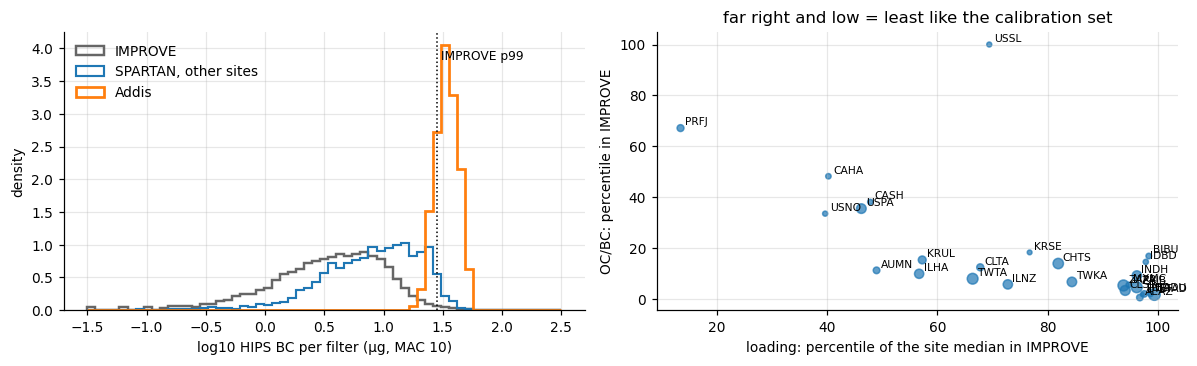

In [6]:
def pct_in(ref, v):
    ref = np.sort(ref[np.isfinite(ref)])
    return 100 * np.searchsorted(ref, v) / len(ref)

ref_ug, ref_ocbc = im.hips_ug.to_numpy(), im.oc_bc.to_numpy()
P99 = np.nanpercentile(ref_ug, 99)
rows = []
for code, g in nm[~nm.excluded & nm.hips_ug.notna()].groupby("code"):
    rows.append({"code": code, "site": SITE_NAME.get(code, code), "n": len(g),
                 "HIPS µg/filter (median)": g.hips_ug.median(),
                 "percentile in IMPROVE": pct_in(ref_ug, g.hips_ug.median()),
                 "share above IMPROVE p99": (g.hips_ug > P99).mean(),
                 "OC/BC (median)": g.oc_bc.median(),
                 "OC/BC percentile in IMPROVE": pct_in(ref_ocbc, g.oc_bc.median()),
                 "EC/PM2.5 (median)": (g.ec_ftir_ugm3 / g.pm25_ugm3).median()})
where = pd.DataFrame(rows).sort_values("percentile in IMPROVE", ascending=False).reset_index(drop=True)
print(f"IMPROVE: median {np.nanmedian(ref_ug):.2f} HIPS µg/filter, p99 {P99:.1f}; median OC/BC {np.nanmedian(ref_ocbc):.1f}")
display(where)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
bins = np.linspace(-1.5, 2.5, 60)
ax[0].hist(np.log10(ref_ug[ref_ug > 0]), bins, density=True, histtype="step", lw=1.6, color="0.4", label="IMPROVE")
ax[0].hist(np.log10(nm.hips_ug[(nm.code != "ETAD") & (nm.hips_ug > 0)]), bins, density=True, histtype="step", lw=1.4, label="SPARTAN, other sites")
ax[0].hist(np.log10(am.hips_ug[ADDIS]), bins, density=True, histtype="step", lw=1.8, color="tab:orange", label="Addis")
ax[0].axvline(np.log10(P99), color="k", ls=":", lw=1); ax[0].text(np.log10(P99), ax[0].get_ylim()[1] * .9, " IMPROVE p99", fontsize=8)
ax[0].set(xlabel="log10 HIPS BC per filter (µg, MAC 10)", ylabel="density"); ax[0].legend(frameon=False)
w = where[where.n >= 20]
ax[1].scatter(w["percentile in IMPROVE"], w["OC/BC percentile in IMPROVE"], s=w.n / 4, alpha=.7)
for _, r in w.iterrows():
    ax[1].annotate(r.code, (r["percentile in IMPROVE"], r["OC/BC percentile in IMPROVE"]), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax[1].set(xlabel="loading: percentile of the site median in IMPROVE", ylabel="OC/BC: percentile in IMPROVE",
          title="far right and low = least like the calibration set")
plt.tight_layout(); plt.show()

**How to read it.** Sites in the bottom-right of the scatter are heavily loaded *and* low in OC relative to BC,
which is where Addis sits. A site whose median is near IMPROVE's 99th percentile is predicted by extrapolation
whatever we do in Sections 4 and 7; only a flag (Section 5) or new reference filters (D) can say how well.

## 2. Out-of-site predictions for every IMPROVE filter

The reference model is the full IMPROVE calibration set, as SPARTAN uses. Each IMPROVE filter is predicted by a model
fitted without any filter from its own site (5 site-grouped folds), for every preprocessing and every k. k is chosen by
the one-standard-error rule on these folds. These predictions are the ground truth for Sections 3, 5 and 7.

spline  k =  4   RMSE 6.06 µg/filter   bias -0.02   R² 0.59   (2 s)


raw     k =  9   RMSE 5.84 µg/filter   bias -0.06   R² 0.62   (3 s)


vibes   k =  5   RMSE 6.36 µg/filter   bias -0.01   R² 0.55   (3 s)


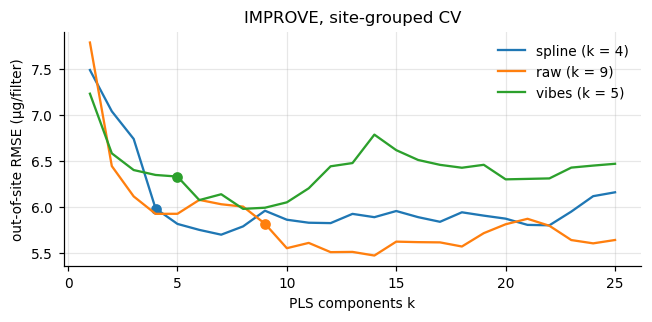

In [7]:
rng = np.random.default_rng(SEED)
FOLDS, NF = site_folds(sites, N_FOLDS, rng)
OOF, KSEL, FOLD_MODELS, CURVE = {}, {}, {}, {}
for prep in PREPS_ALL:
    t0 = time.time()
    X = XI[prep]
    pred, err, models = np.full((len(y), K_MAX), np.nan), np.full((NF, K_MAX), np.nan), []
    for f in range(NF):
        tr = FOLDS != f
        m = PLS().fit(X[tr], y[tr])
        pred[~tr, :m.K] = m.predict(X[~tr])
        err[f, :m.K] = np.sqrt(((pred[~tr, :m.K] - y[~tr, None]) ** 2).mean(0))
        models.append(m)
    k = one_se(err)
    OOF[prep], KSEL[prep], FOLD_MODELS[prep], CURVE[prep] = pred, k, models, err
    p = pred[:, k - 1]
    print(f"{prep:6s}  k = {k:2d}   RMSE {rmse(p - y):.2f} µg/filter   bias {np.mean(p - y):+.2f}   "
          f"R² {1 - np.sum((p - y) ** 2) / np.sum((y - y.mean()) ** 2):.2f}   ({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(6, 3))
for prep in PREPS_ALL:
    ax.plot(range(1, K_MAX + 1), np.nanmean(CURVE[prep], 0), label=f"{prep} (k = {KSEL[prep]})")
    ax.plot(KSEL[prep], np.nanmean(CURVE[prep], 0)[KSEL[prep] - 1], "o", color=ax.lines[-1].get_color())
ax.set(xlabel="PLS components k", ylabel="out-of-site RMSE (µg/filter)", title="IMPROVE, site-grouped CV")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 3. Where does the reference model fail inside IMPROVE, against TOR?

The IMPROVE filters most like Addis are grouped five ways, each the most extreme 5 % of IMPROVE on one variable that a
SPARTAN filter also has: HIPS loading per filter, OC/BC (TOR OC over HIPS BC, the Addis definition), smoke (non-soil
potassium), the six urban IMPROVE sites, and spectra most correlated with the median Addis spectrum. Groups are not
defined on TOR EC itself, which would bias the error by selection. The last two columns compare the same predictions
with HIPS instead of TOR, the only comparison SPARTAN can make.

,n,bias,rel_bias,rmse,rel_rmse,mean TOR µg,slope vs TOR,intercept vs TOR,slope vs HIPS,intercept vs HIPS
group,,,,,,,,,,
Heavy loading,620,-9.896,-0.332,24.013,0.805,29.831,0.530,4.113,0.935,-2.454
Low OC/BC,620,-1.324,-0.302,6.266,1.429,4.383,0.231,2.045,0.263,1.563
Smoke (non-soil K),619,-1.082,-0.061,18.362,1.042,17.620,0.653,5.024,1.263,-1.029
Urban sites,630,-6.994,-0.350,13.673,0.684,19.993,0.399,5.023,0.596,1.735
Addis-like spectra,620,-0.889,-0.118,4.685,0.621,7.547,0.396,3.668,0.416,3.169
None of these,10027,0.567,0.134,2.655,0.626,4.240,0.883,1.062,0.723,1.947


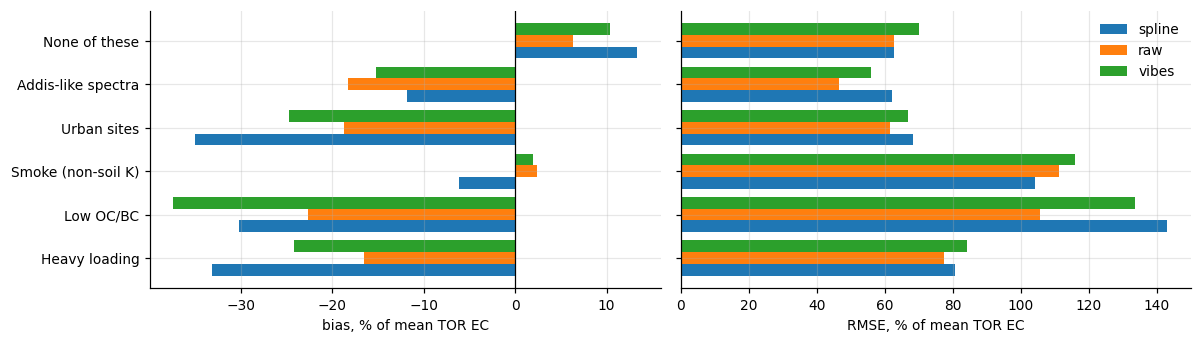

In [8]:
addis_median = {p: np.median(XA[p][ADDIS], axis=0) for p in PREPS_ALL}
im["addis_corr"] = corr_to(XI[MAIN], addis_median[MAIN], corr_mask(MAIN))
GROUP_DEF = {"Heavy loading": ("hips_ug", 1), "Low OC/BC": ("oc_bc", -1), "Smoke (non-soil K)": ("nsk_ugm3", 1),
             "Urban sites": ("urban", 1), "Addis-like spectra": ("addis_corr", 1)}


def group_masks(df, ref=None):
    """The five hard groups (thresholds from `ref`, default `df`) and the rest."""
    ref = df if ref is None else ref
    g = {}
    for name, (col, sign) in GROUP_DEF.items():
        if col == "urban":
            g[name] = df.urban.astype(bool).to_numpy()
        elif sign > 0:
            g[name] = (df[col] >= np.nanpercentile(ref[col], 100 - GROUP_PCT)).to_numpy()
        else:
            g[name] = (df[col] <= np.nanpercentile(ref[col], GROUP_PCT)).to_numpy()
    g["None of these"] = ~np.any(list(g.values()), axis=0)
    return g


G = group_masks(im)
rows = []
for prep in PREPS_ALL:
    p = OOF[prep][:, KSEL[prep] - 1]
    for name, m in G.items():
        s_t, i_t = ols(y[m], p[m])
        s_h, i_h = ols(im.hips_ug.to_numpy()[m], p[m])
        rows.append({"preprocessing": prep, "group": name, **score(p[m], y[m]),
                     "mean TOR µg": y[m].mean(), "slope vs TOR": s_t, "intercept vs TOR": i_t,
                     "slope vs HIPS": s_h, "intercept vs HIPS": i_h})
FAIL = pd.DataFrame(rows)
display(FAIL[FAIL.preprocessing == MAIN].drop(columns="preprocessing").set_index("group"))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
names = list(G)
for j, prep in enumerate(PREPS_ALL):
    d = FAIL[FAIL.preprocessing == prep].set_index("group").loc[names]
    ax[0].barh(np.arange(len(names)) + j * 0.27, 100 * d.rel_bias, 0.27, label=prep)
    ax[1].barh(np.arange(len(names)) + j * 0.27, 100 * d.rel_rmse, 0.27, label=prep)
ax[0].set(yticks=np.arange(len(names)) + 0.27, yticklabels=names, xlabel="bias, % of mean TOR EC"); ax[0].axvline(0, color="k", lw=.8)
ax[1].set(xlabel="RMSE, % of mean TOR EC"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

**How to read it.** If the Addis-like IMPROVE groups are predicted about as well as the rest against TOR, the
Addis problem is not reproduced inside IMPROVE: either Addis is beyond IMPROVE's range (Section 1) or the gap is in the
HIPS reference (compare the TOR and HIPS columns: a slope against HIPS well below the slope against TOR is the
reference gap seen before, MAC 7.8–8.2 on smoke filters). If a group *is* badly predicted against TOR, that group is a
place where B or A could help, and it is testable. Part of any negative bias in the heavy-loading group is the usual
shrinkage of a regression toward the mean at its extremes ("None of these" has slope 0.88, not 1); a group whose
filters are *not* heavy but are still badly under-predicted (low OC/BC) points at composition instead.

## 4. Option B: do specialist calibrations beat the full calibration set on the filters they are built for?

A fair test of "several models and a rule to pick one", entirely inside IMPROVE with TOR as the truth. In each of
`N_REPEATS` splits, 30 % of IMPROVE sites are held out. The hard groups are found among the held-out filters (thresholds
from the training sites only). Each target group is then predicted by:

* **full**: the whole training calibration set (the reference);
* **same kind**: the `N_SELECT` training filters most like the group on its own variable (heaviest, lowest OC/BC,
  smokiest, urban, most Addis-like), i.e. a rule that picks a specialist by a measured property;
* **target analogs**: the training filters whose spectra correlate best with the target group's median spectrum, the
  recipe of the seasonal Addis calibrations;
* **local**: each target filter's own `N_SELECT` nearest training spectra (a sample of `LOCAL_PER_GROUP` filters).

k is chosen inside each calibration set by site-grouped CV. The local models are also run on a sample of ordinary
held-out filters (the "None of these" row), to tell "better on hard filters" from "better everywhere". A specialist is only useful if it wins on its target
*and* the rule picking it is available for a SPARTAN filter; the `outside` column shows what it costs on the held-out
filters it was not built for, i.e. when the rule picks wrongly.

In [9]:
ZN = {p: unit_rows(XI[p], corr_mask(p)) for p in PREPS}
usites = np.unique(sites)
rng = np.random.default_rng(SEED + 1)
RUNS = []
t_all = time.time()
for r in range(N_REPEATS):
    t0 = time.time()
    H = np.isin(sites, rng.choice(usites, int(round((1 - TRAIN_SHARE) * len(usites))), replace=False))
    Tr = ~H
    gm = group_masks(im, im[Tr])
    for prep in PREPS:
        X, mask = XI[prep], corr_mask(prep)
        k_full = cv_k(X[Tr], y[Tr], sites[Tr], rng)
        p_full = PLS(k_full).fit(X[Tr], y[Tr]).predict(X)[:, k_full - 1]
        for name, (col, sign) in GROUP_DEF.items():
            tgt = gm[name] & H
            if tgt.sum() < 20:
                continue
            outside = H & ~tgt
            rec = {"repeat": r, "preprocessing": prep, "group": name, "n_target": int(tgt.sum()), "k full": k_full,
                   "full rmse": rmse(p_full[tgt] - y[tgt]), "full bias": np.mean(p_full[tgt] - y[tgt]),
                   "full rmse outside": rmse(p_full[outside] - y[outside]), "mean TOR": y[tgt].mean()}
            if col == "urban":
                sel_same = np.flatnonzero(Tr & im.urban.to_numpy())
            else:
                v = sign * im[col].to_numpy(float)
                v[~Tr | ~np.isfinite(v)] = -np.inf
                sel_same = np.argsort(-v)[:N_SELECT]
            c = corr_to(X, np.median(X[tgt], 0), mask)
            c[~Tr] = -np.inf
            sel_analog = np.argsort(-c)[:N_SELECT]
            for rule, sel in (("same kind", sel_same), ("target analogs", sel_analog)):
                if len(sel) < 60:
                    continue
                k = cv_k(X[sel], y[sel], sites[sel], rng)
                pr = PLS(k).fit(X[sel], y[sel]).predict(X)[:, k - 1]
                rec.update({f"{rule} k": k, f"{rule} rmse": rmse(pr[tgt] - y[tgt]), f"{rule} bias": np.mean(pr[tgt] - y[tgt]),
                            f"{rule} rmse outside": rmse(pr[outside] - y[outside])})
            if LOCAL_PER_GROUP:
                idx = rng.choice(np.flatnonzero(tgt), min(LOCAL_PER_GROUP, int(tgt.sum())), replace=False)
                trows = np.flatnonzero(Tr)
                C = ZN[prep][idx] @ ZN[prep][trows].T
                kk = rec.get("target analogs k", k_full)
                pl = [PLS(kk).fit(X[nn], y[nn]).predict(X[i:i + 1])[0, kk - 1]
                      for i, nn in zip(idx, (trows[np.argpartition(-row, N_SELECT)[:N_SELECT]] for row in C))]
                rec.update({"local rmse": rmse(np.array(pl) - y[idx]), "local bias": np.mean(np.array(pl) - y[idx]),
                            "full rmse (local sample)": rmse(p_full[idx] - y[idx])})
            RUNS.append(rec)
        # the same local models on ordinary held-out filters: is "local" better only on hard filters, or on all of them?
        rest = gm["None of these"] & H
        if LOCAL_PER_GROUP and rest.sum() >= 20:
            idx = rng.choice(np.flatnonzero(rest), min(2 * LOCAL_PER_GROUP, int(rest.sum())), replace=False)
            trows = np.flatnonzero(Tr)
            C = ZN[prep][idx] @ ZN[prep][trows].T
            pl = [PLS(k_full).fit(X[nn], y[nn]).predict(X[i:i + 1])[0, k_full - 1]
                  for i, nn in zip(idx, (trows[np.argpartition(-row, N_SELECT)[:N_SELECT]] for row in C))]
            RUNS.append({"repeat": r, "preprocessing": prep, "group": "None of these", "n_target": int(rest.sum()),
                         "k full": k_full, "mean TOR": y[idx].mean(), "full rmse": np.nan,
                         "full bias": np.mean(p_full[idx] - y[idx]), "local rmse": rmse(np.array(pl) - y[idx]),
                         "local bias": np.mean(np.array(pl) - y[idx]), "full rmse (local sample)": rmse(p_full[idx] - y[idx])})
    print(f"split {r + 1}/{N_REPEATS}: {time.time() - t0:.0f} s")
RUNS = pd.DataFrame(RUNS)
print(f"Section 4: {time.time() - t_all:.0f} s")

split 1/10: 25 s


split 2/10: 23 s


split 3/10: 21 s


split 4/10: 45 s


split 5/10: 195 s


split 6/10: 228 s


split 7/10: 18 s


split 8/10: 24 s


split 9/10: 22 s


split 10/10: 21 s
Section 4: 622 s


,preprocessing,group,rule,splits,median n target,"RMSE change vs full, % (median)","RMSE change, % (10th-90th pct)",wins (share of splits),"bias full, % of TOR","RMSE outside its target, % change"
0,spline,Heavy loading,same kind,10,203.500,5.360,-3 to +21,0.200,-32.893,317.119
1,spline,Heavy loading,target analogs,10,203.500,-0.046,-18 to +64,0.500,-32.893,89.152
2,spline,Heavy loading,local,10,203.500,-10.764,-35 to +24,0.600,-32.893,NaN
3,spline,Low OC/BC,same kind,10,190.000,-8.164,-15 to +17,0.800,-39.611,207.928
4,spline,Low OC/BC,target analogs,10,190.000,9.931,+6 to +33,0.000,-39.611,48.138
5,spline,Low OC/BC,local,10,190.000,4.011,-12 to +10,0.300,-39.611,NaN
6,spline,Smoke (non-soil K),same kind,10,197.500,16.080,-13 to +39,0.200,-6.784,32.015
7,spline,Smoke (non-soil K),target analogs,10,197.500,40.562,+7 to +84,0.000,-6.784,25.826
8,spline,Smoke (non-soil K),local,10,197.500,0.525,-50 to +96,0.500,-6.784,NaN
9,spline,Urban sites,same kind,10,209.000,-13.645,-34 to +28,0.700,-35.070,56.844


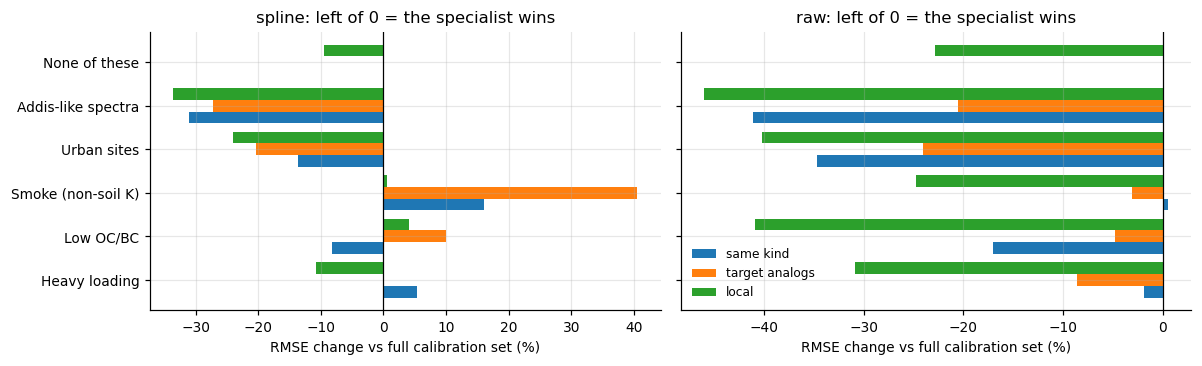

In [10]:
def spec_summary(runs):
    rows = []
    for (prep, group), d in runs.groupby(["preprocessing", "group"], sort=False):
        for rule in ("same kind", "target analogs", "local"):
            col = f"{rule} rmse"
            if col not in d or d[col].isna().all():
                continue
            base = d["full rmse (local sample)"] if rule == "local" else d["full rmse"]
            ok = d[col].notna()
            change = 100 * (d.loc[ok, col] / base[ok] - 1)
            row = {"preprocessing": prep, "group": group, "rule": rule, "splits": int(ok.sum()),
                   "median n target": d.n_target.median(),
                   "RMSE change vs full, % (median)": change.median(),
                   "RMSE change, % (10th-90th pct)": f"{change.quantile(.1):+.0f} to {change.quantile(.9):+.0f}",
                   "wins (share of splits)": (change < 0).mean(),
                   "bias full, % of TOR": 100 * (d["full bias"] / d["mean TOR"]).median(),
                   f"bias {rule}, % of TOR": 100 * (d[f"{rule} bias"] / d["mean TOR"]).median()}
            if f"{rule} rmse outside" in d:
                row["RMSE outside its target, % change"] = 100 * (d[f"{rule} rmse outside"] / d["full rmse outside"] - 1).median()
            rows.append(row)
    return pd.DataFrame(rows)


SPEC = spec_summary(RUNS)
GROUPS_PLUS = list(GROUP_DEF) + ["None of these"]
display(SPEC.drop(columns=[c for c in SPEC if c.startswith("bias ") and c != "bias full, % of TOR"]))

fig, axes = plt.subplots(1, len(PREPS), figsize=(5.5 * len(PREPS), 3.4), sharey=True)
for ax, prep in zip(np.atleast_1d(axes), PREPS):
    d = SPEC[SPEC.preprocessing == prep]
    for j, rule in enumerate(("same kind", "target analogs", "local")):
        e = d[d.rule == rule].set_index("group").reindex(GROUPS_PLUS)
        ax.barh(np.arange(len(GROUPS_PLUS)) + j * .27, e["RMSE change vs full, % (median)"], .27, label=rule)
    ax.axvline(0, color="k", lw=.8)
    ax.set(yticks=np.arange(len(GROUPS_PLUS)) + .27, yticklabels=GROUPS_PLUS, xlabel="RMSE change vs full calibration set (%)",
           title=f"{prep}: left of 0 = the specialist wins")
np.atleast_1d(axes)[-1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**How to read it.** A rule is worth pursuing only if it wins in most splits (share near 1) by a margin larger than
its spread, *and* does not do much worse outside its target. "Same kind" rules need the defining variable for a SPARTAN
filter: HIPS loading and spectra are available everywhere; OC/BC needs FTIR OC (an FTIR product itself) and smoke needs
XRF K; "target analogs" and "local" need only the spectrum. If no rule wins on the groups most like Addis, B is not
supported by the data we have, and that is a result worth reporting. A "local" calibration needs no rule at all
(each filter picks its own neighbours from its spectrum), so if it wins on the hard groups *and* on "None of these", it
is really a candidate for option A: one better method for every filter.

## 5. Option C: can a filter's own spectrum flag that its FTIR EC is likely wrong?

Every IMPROVE filter has an out-of-site prediction (Section 2, `MAIN` preprocessing) and therefore a known error
against TOR. A filter is **impacted** when |FTIR − TOR| exceeds both `ABS_TOL` µg and `REL_TOL` of TOR. The flag is a
gradient-boosted classifier that predicts "impacted" from things every SPARTAN filter has:

* **spectrum only**: the model's score distance T² and spectral residual Q (how far the spectrum is from the
  calibration set, in and out of the model's components), the predicted EC per filter, and band areas on the raw
  spectrum (Si–O dust near 1035, PTFE residue 1150/1210, carbonyl 1720, C–H 2900, O–H/N–H 3300, their ratios, and the
  offset at 3800–4000 cm⁻¹);
* **spectrum + HIPS**: the same plus HIPS µg per filter and FTIR ÷ HIPS.

The flag is trained and scored with the same site-grouped folds, so its score is for sites it has not seen. It is
compared with single quantities (T², Q, loading alone): a flag only earns its complexity if it beats them.

base rate: 19.1% of IMPROVE filters are impacted at k = 4 (spline)


,flag,AUC,average precision,impacted share among top 10 % flagged,share of impacted caught by top 10 %
0,spectrum only,0.759,0.478,0.575,0.302
1,spectrum + HIPS,0.885,0.711,0.809,0.424
2,t2 alone,0.581,0.268,0.317,0.166
3,q alone,0.681,0.340,0.392,0.206
4,pred_ug alone,0.621,0.262,0.276,0.145
5,hips_ug alone,0.522,0.237,0.248,0.130
6,ftir_over_hips alone,0.626,0.341,0.376,0.197
7,sio_1035 alone,0.535,0.246,0.302,0.159


,filters,impacted share,mean flag (spectrum + HIPS)
Heavy loading,620.000,0.224,0.218
Low OC/BC,620.000,0.213,0.211
Smoke (non-soil K),619.000,0.237,0.236
Urban sites,630.000,0.148,0.157
Addis-like spectra,620.000,0.202,0.187
None of these,"10,027.000",0.190,0.188


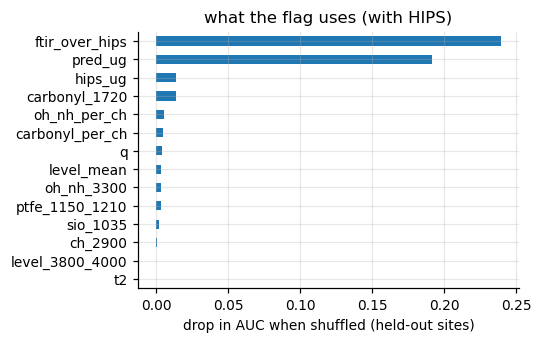

In [11]:
k_main = KSEL[MAIN]
t2_I, Q_I = np.zeros(len(y)), np.zeros(len(y))
for f, m in enumerate(FOLD_MODELS[MAIN]):
    te = FOLDS == f
    t2_I[te], Q_I[te] = m.distances(XI[MAIN][te], k_main)
pred_I = OOF[MAIN][:, k_main - 1]
FI = spectral_features(XI["raw"])
FI["t2"], FI["q"], FI["pred_ug"] = t2_I, Q_I, pred_I
FI["hips_ug"] = im.hips_ug.to_numpy()
FI["ftir_over_hips"] = pred_I / np.clip(FI.hips_ug, 0.05, None)
ERR = pred_I - y
IMPACTED = (np.abs(ERR) > ABS_TOL) & (np.abs(ERR) > REL_TOL * np.abs(y))
SPECTRUM_ONLY = list(BANDS) + ["level_3800_4000", "level_mean", "carbonyl_per_ch", "oh_nh_per_ch", "t2", "q", "pred_ug"]
WITH_HIPS = SPECTRUM_ONLY + ["hips_ug", "ftir_over_hips"]
new_clf = lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                                 l2_regularization=1.0, random_state=SEED)


def cv_flag(cols):
    prob = np.zeros(len(y))
    for f in range(NF):
        tr = FOLDS != f
        prob[~tr] = new_clf().fit(FI.loc[tr, cols], IMPACTED[tr]).predict_proba(FI.loc[~tr, cols])[:, 1]
    return prob


def flag_scores(prob, label):
    top = prob >= np.quantile(prob, 0.9)
    return {"flag": label, "AUC": roc_auc_score(IMPACTED, prob), "average precision": average_precision_score(IMPACTED, prob),
            "impacted share among top 10 % flagged": IMPACTED[top].mean(), "share of impacted caught by top 10 %": IMPACTED[top].sum() / IMPACTED.sum()}


PROB = {"spectrum only": cv_flag(SPECTRUM_ONLY), "spectrum + HIPS": cv_flag(WITH_HIPS)}
rows = [flag_scores(p, k) for k, p in PROB.items()]
for c in ["t2", "q", "pred_ug", "hips_ug", "ftir_over_hips", "sio_1035"]:
    v = FI[c].to_numpy()
    v = np.where(np.isfinite(v), v, np.nanmedian(v))
    auc = roc_auc_score(IMPACTED, v)
    rows.append(flag_scores(v if auc >= .5 else -v, f"{c} alone"))
FLAGS = pd.DataFrame(rows)
print(f"base rate: {IMPACTED.mean():.1%} of IMPROVE filters are impacted at k = {k_main} ({MAIN})")
display(FLAGS)

# which preprocessing's errors? the flag is for MAIN; the same table per group shows where impacted filters are
display(pd.DataFrame({name: {"filters": int(m.sum()), "impacted share": IMPACTED[m].mean(),
                             "mean flag (spectrum + HIPS)": PROB["spectrum + HIPS"][m].mean()} for name, m in G.items()}).T)

FLAG_COLS = WITH_HIPS if FLAGS.set_index("flag").AUC["spectrum + HIPS"] >= FLAGS.set_index("flag").AUC["spectrum only"] + 0.02 else SPECTRUM_ONLY
hold = FOLDS == 0
pi = permutation_importance(new_clf().fit(FI.loc[~hold, FLAG_COLS], IMPACTED[~hold]), FI.loc[hold, FLAG_COLS], IMPACTED[hold],
                            scoring="roc_auc", n_repeats=5, random_state=SEED)
imp = pd.Series(pi.importances_mean, FLAG_COLS).sort_values()
fig, ax = plt.subplots(figsize=(5, 3.2)); imp.plot.barh(ax=ax)
ax.set(xlabel="drop in AUC when shuffled (held-out sites)", title=f"what the flag uses ({'with' if FLAG_COLS is WITH_HIPS else 'without'} HIPS)")
plt.tight_layout(); plt.show()

**How to read it.** AUC 0.5 is a coin toss, 1.0 is perfect. The flag is useful if it clearly beats T² or Q alone
(the standard "outside the calibration domain" test), and if the share of impacted filters among the top 10 % flagged
is well above the base rate. Note the limit: IMPROVE can teach the flag what error looks like *inside* IMPROVE's
range. For filters beyond it, Section 6 reports a separate **outside the IMPROVE range** mark, which says "extrapolating"
without saying by how much.

## 6. Applying the flag to every SPARTAN filter: which sites and seasons?

The `MAIN` model and the flag are refitted on all of IMPROVE and applied to every SPARTAN PM2.5 filter and to the
Addis evaluation set. Each site-season gets: the share flagged, the share outside the IMPROVE range (any of loading,
predicted EC, T², Q, dust or PTFE beyond IMPROVE's 0.5–99.5 percentiles), and, as a cross-check only, how FTIR EC
compares with HIPS BC there (this workbook's model and SPARTAN's published EC, median ratio and Deming fit with the
Addis error ratio). Seasons follow each site's calendar in the gallery.

**By site** (sorted by the + HIPS flag)

,code,site,n,mean flag (spectrum),mean flag (+ HIPS),flagged share (+ HIPS),outside IMPROVE range,this model ÷ HIPS (median),published ÷ HIPS (median),published vs HIPS slope,intercept,intercept ÷ mean
9,ETAD,"Addis Ababa, Ethiopia",252,0.261,0.791,0.909,0.361,0.256,0.910,2.216,-5.790,-1.193
2,BDDU,"Dhaka, Bangladesh",60,0.570,0.593,0.683,0.100,0.327,0.685,1.138,-1.599,-0.484
15,INJA,"Jaipur, India",91,0.278,0.398,0.440,0.154,0.380,0.686,0.953,-0.944,-0.257
26,ZAJB,"Johannesburg, South Africa",231,0.227,0.358,0.316,0.065,0.455,0.829,0.938,-0.233,-0.112
7,CLST,"Santiago, Chile",203,0.223,0.326,0.286,0.044,0.438,0.666,1.411,-1.273,-0.575
27,ZAPR,"Pretoria, South Africa",223,0.225,0.320,0.278,0.063,0.498,0.837,0.932,-0.145,-0.076
10,ETBI,"Bishoftu, Ethiopia",63,0.324,0.309,0.302,0.095,0.285,0.561,0.796,-0.626,-0.426
0,AEAZ,"Abu Dhabi, UAE",84,0.634,0.257,0.202,0.310,0.598,0.610,1.384,-1.946,-1.047
3,BIBU,"Bujumbura, Burundi",60,0.287,0.254,0.167,0.167,0.561,0.988,1.729,-2.597,-0.662
13,ILNZ,"Rehovot, Israel",148,0.226,0.231,0.169,0.108,0.546,0.771,0.826,-0.073,-0.083


**Addis evaluation set by season**

,season,n,mean flag (spectrum),mean flag (+ HIPS),flagged share (+ HIPS),outside IMPROVE range,this model ÷ HIPS (median),published ÷ HIPS (median),published vs HIPS slope,intercept,intercept ÷ mean
0,Belg (Mar-May),60,0.292,0.845,1.000,0.317,0.250,0.983,1.886,-4.170,-0.854
1,Dry (Oct-Feb),102,0.233,0.898,0.990,0.206,0.211,0.777,1.412,-2.620,-0.772
2,Kiremt (Jun-Sep),71,0.262,0.788,0.972,0.718,0.303,1.286,2.189,-5.095,-0.711


**Site-seasons with at least 10 filters, top 20**

,code,season,n,mean flag (spectrum),mean flag (+ HIPS),flagged share (+ HIPS),outside IMPROVE range,this model ÷ HIPS (median),published ÷ HIPS (median),published vs HIPS slope,intercept,intercept ÷ mean
39,ETAD,Bega (Oct–Jan),87,0.235,0.842,0.920,0.218,0.221,0.771,1.251,-2.074,-0.618
40,ETAD,Belg (Feb–May),89,0.284,0.792,0.910,0.236,0.245,0.879,1.777,-3.748,-0.856
41,ETAD,Kiremt (Jun–Sep),70,0.262,0.787,0.971,0.714,0.311,1.275,2.177,-5.048,-0.704
10,BDDU,Monsoon (Jun–Sep),42,0.540,0.692,0.857,0.048,0.318,0.677,0.946,-0.909,-0.305
65,INJA,Post-monsoon (Oct–Dec),30,0.307,0.544,0.667,0.333,0.405,0.769,NaN,NaN,NaN
66,INJA,Pre-monsoon (Mar–May),19,0.242,0.523,0.632,0.053,0.210,0.686,NaN,NaN,NaN
43,ETBI,Bega (Oct–Jan),33,0.317,0.515,0.576,0.152,0.285,0.561,0.796,-0.626,-0.426
113,ZAJB,Spring (Sep–Nov),62,0.246,0.488,0.500,0.032,0.383,0.752,0.820,-0.086,-0.046
13,BIBU,Long dry season (Jun–Aug),15,0.341,0.478,0.467,0.533,0.504,1.155,NaN,NaN,NaN
120,ZAPR,Winter (Jun–Aug),63,0.212,0.453,0.444,0.048,0.431,0.826,1.195,-0.937,-0.371


cross-check with the spectrum-only flag over 54 site-seasons: Spearman(flag, Deming intercept ÷ mean) = -0.33 (negative = flag high where the intercept is negative); (flag, |log published ÷ HIPS|) = +0.25


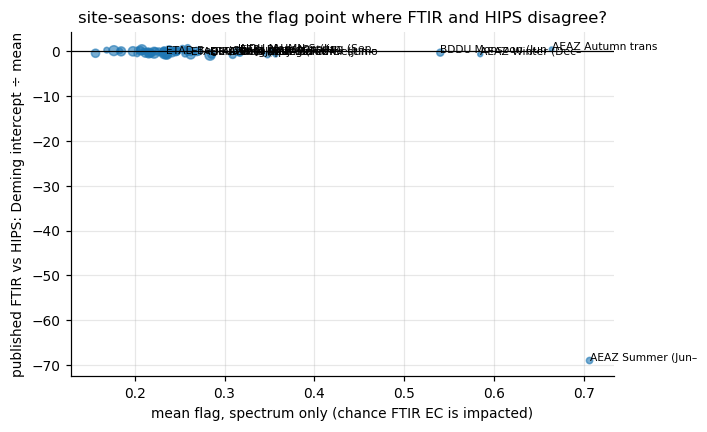

In [12]:
ALL = {MAIN: PLS().fit(XI[MAIN], y)}
# both flags: "+ HIPS" is the better-validated one, but it uses FTIR ÷ HIPS as an input, so only the spectrum-only flag
# can be checked against the FTIR-HIPS disagreement without going in a circle
FINAL = {"spectrum": (new_clf().fit(FI[SPECTRUM_ONLY], IMPACTED), SPECTRUM_ONLY),
         "+ HIPS": (new_clf().fit(FI[WITH_HIPS], IMPACTED), WITH_HIPS)}
RANGE_COLS = ["hips_ug", "pred_ug", "t2", "q", "sio_1035", "ptfe_1150_1210"]
LO, HI = FI[RANGE_COLS].quantile(0.005), FI[RANGE_COLS].quantile(0.995)


def apply_flag(Xmain, Xraw, hips_ug):
    pred = ALL[MAIN].predict(Xmain)[:, k_main - 1]
    t2, Q = ALL[MAIN].distances(Xmain, k_main)
    F = spectral_features(Xraw)
    F["t2"], F["q"], F["pred_ug"], F["hips_ug"] = t2, Q, pred, hips_ug
    F["ftir_over_hips"] = pred / np.clip(hips_ug, 0.05, None)
    prob = {name: clf.predict_proba(F[cols])[:, 1] for name, (clf, cols) in FINAL.items()}
    outside = ((F[RANGE_COLS] < LO) | (F[RANGE_COLS] > HI)).any(axis=1).to_numpy()
    return prob, outside, pred


net, add = nm.copy(), am.copy()
for d, Xm, Xr in ((net, XN[MAIN], XN["raw"]), (add, XA[MAIN], XA["raw"])):
    prob, d["outside_range"], pred = apply_flag(Xm, Xr, d.hips_ug.to_numpy())
    d["flag_spectrum"], d["flag_hips"] = prob["spectrum"], prob["+ HIPS"]
    d["ec_this_model"] = pred / d.volume_m3.where(d.volume_m3 > 0)
net = net[~net.excluded]


def site_season_table(d, by):
    rows = []
    for key, g in d.groupby(by, dropna=False):
        ok = g.hips_bc.notna() & g.ec_ftir_ugm3.notna() & (g.hips_bc > 0)
        row = dict(zip(by, key if isinstance(key, tuple) else (key,)))
        row.update({"n": len(g), "mean flag (spectrum)": g.flag_spectrum.mean(), "mean flag (+ HIPS)": g.flag_hips.mean(),
                    "flagged share (+ HIPS)": (g.flag_hips >= FLAG_AT).mean(),
                    "outside IMPROVE range": g.outside_range.mean(),
                    "this model ÷ HIPS (median)": (g.ec_this_model / g.hips_bc)[ok].median(),
                    "published ÷ HIPS (median)": (g.ec_ftir_ugm3 / g.hips_bc)[ok].median()})
        if ok.sum() >= 15:
            s, i = deming(g.hips_bc[ok], g.ec_ftir_ugm3[ok], LAMBDA_ADDIS)
            row.update({"published vs HIPS slope": s, "intercept": i, "intercept ÷ mean": i / g.ec_ftir_ugm3[ok].mean()})
        rows.append(row)
    return pd.DataFrame(rows)


net["site"] = net.code.map(SITE_NAME).fillna(net.code)
SITES = site_season_table(net, ["code", "site"]).sort_values("mean flag (+ HIPS)", ascending=False)
SITE_SEASONS = site_season_table(net, ["code", "season"]).query("n >= 10").sort_values("mean flag (+ HIPS)", ascending=False)
add["ec_ftir_ugm3"] = add.ec_published_ugm3
ADDIS_SEASONS = site_season_table(add[ADDIS], ["season"])
display(Markdown("**By site** (sorted by the + HIPS flag)")); display(SITES)
display(Markdown("**Addis evaluation set by season**")); display(ADDIS_SEASONS)
display(Markdown("**Site-seasons with at least 10 filters, top 20**")); display(SITE_SEASONS.head(20))

ok = SITE_SEASONS["intercept ÷ mean"].notna()
FS = SITE_SEASONS["mean flag (spectrum)"]
rho1 = spearmanr(FS[ok], SITE_SEASONS["intercept ÷ mean"][ok]).statistic
rho2 = spearmanr(FS[ok], np.abs(np.log(SITE_SEASONS["published ÷ HIPS (median)"][ok]))).statistic
print(f"cross-check with the spectrum-only flag over {ok.sum()} site-seasons: Spearman(flag, Deming intercept ÷ mean) = "
      f"{rho1:+.2f} (negative = flag high where the intercept is negative); (flag, |log published ÷ HIPS|) = {rho2:+.2f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(FS[ok], SITE_SEASONS["intercept ÷ mean"][ok], s=SITE_SEASONS.n[ok] / 2, alpha=.6)
for _, r in SITE_SEASONS[ok].iterrows():
    if r["mean flag (spectrum)"] > FS.quantile(.8) or r.code == "ETAD":
        ax.annotate(f"{r.code} {str(r.season)[:12]}", (r["mean flag (spectrum)"], r["intercept ÷ mean"]), fontsize=7)
ax.axhline(0, color="k", lw=.8)
ax.set(xlabel="mean flag, spectrum only (chance FTIR EC is impacted)", ylabel="published FTIR vs HIPS: Deming intercept ÷ mean",
       title="site-seasons: does the flag point where FTIR and HIPS disagree?")
plt.tight_layout(); plt.show()

**How to read it.** The site and site-season tables are the answer to "which sites or seasons need attention",
with two different meanings: *flagged* = looks like the IMPROVE filters the calibration got wrong; *outside range* =
beyond anything IMPROVE can vouch for. The "+ HIPS" flag is the better one on IMPROVE but partly restates the FTIR–HIPS
disagreement at SPARTAN; the spectrum-only flag is weaker but independent of HIPS, which is why the cross-check uses it. The HIPS columns are not a verdict (HIPS ÷ 10 assumes the MAC), but if the flag
and the FTIR–HIPS disagreement point at the same site-seasons, that is independent support for both.

## 6b. Experimental: what does the flag actually see?

The flag in Section 5 mixes loading proxies (predicted EC, spectrum size, band areas) with the spectral distance T²/Q,
so its AUC cannot say whether the *distance* tells us anything a scale could not. Three checks, all on the same
held-out-site folds and the same "impacted" definition:

* **Ablation ladder.** The flag is refitted on growing sets of inputs, starting from **measured loading alone**
  (gravimetric PM2.5 µg per filter, IMPROVE MF × volume; SPARTAN weighs the same PTFE filter). Each rung's AUC has a
  95 % interval from resampling held-out sites, and its gain over loading alone is paired on the same filters. Rungs
  marked *not at SPARTAN* use HIPS, which the FTIR–HIPS disagreement shares, so they are circular there.
* **Error against coverage.** Keep only the filters a score rates least risky: how much error is left, and how many
  impacted filters still get through, as the kept share falls from 100 %? An oracle (keep by the true error) and a
  random rule bracket every curve.
* **Missed failures.** At a flag rate of 10 % (keep 90 %), the impacted filters the best SPARTAN-usable flag lets
  through: what they look like, and where Addis sits on the same loading × distance map.

Every rung is a prediction-time quantity; none uses the filter's TOR.

In [13]:
mass_file = BUNDLE / "improve_mass.csv"
if mass_file.exists():
    mass = pd.read_csv(mass_file)
    FI["pm_ug"] = im[["filter_id"]].merge(mass, on="filter_id", how="left", validate="one_to_one").pm25_ugm3.to_numpy() * im.volume_m3.to_numpy()
else:
    print("improve_mass.csv is not in this bundle (run the bundle builder with --mass-only); the loading rungs use HIPS µg instead")
    FI["pm_ug"] = FI.hips_ug
pm_ugm3 = FI.pm_ug.to_numpy() / im.volume_m3.to_numpy()
FI["fe_frac"] = im.fe_ugm3.to_numpy() / pm_ugm3
FI["nsk_frac"] = im.nsk_ugm3.to_numpy() / pm_ugm3
print(f"gravimetric PM2.5 on {np.isfinite(FI.pm_ug).sum():,} of {len(FI):,} IMPROVE filters; median {np.nanmedian(FI.pm_ug):.0f} µg per filter")

# (label, inputs, usable at SPARTAN without HIPS)
RUNGS = [("Loading: weighed PM2.5", ["pm_ug"], True),
         ("Loading: spectrum size", ["level_mean", "ch_2900"], True),
         ("Distance: T² + Q", ["t2", "q"], True),
         ("Loading + distance", ["pm_ug", "t2", "q"], True),
         ("+ predicted EC", ["pm_ug", "t2", "q", "pred_ug"], True),
         ("+ band features", ["pm_ug"] + SPECTRUM_ONLY, True),
         ("+ XRF Fe, non-soil K", ["pm_ug"] + SPECTRUM_ONLY + ["fe_frac", "nsk_frac"], True),
         ("+ HIPS", ["pm_ug"] + SPECTRUM_ONLY + ["fe_frac", "nsk_frac", "hips_ug", "ftir_over_hips"], False)]
RISK = {label: cv_flag(cols) for label, cols, _ in RUNGS}

# site bootstrap: resample held-out sites, AUC per rung and its paired gain over loading alone
u_sites = np.unique(sites)
site_rows = {s: np.flatnonzero(sites == s) for s in u_sites}
rng = np.random.default_rng(SEED + 6)
BOOT = {label: [] for label in RISK}
base = RUNGS[0][0]
for _ in range(300):
    idx = np.concatenate([site_rows[s] for s in rng.choice(u_sites, len(u_sites), replace=True)])
    if IMPACTED[idx].all() or not IMPACTED[idx].any():
        continue
    a0 = roc_auc_score(IMPACTED[idx], RISK[base][idx])
    for label, r in RISK.items():
        a = roc_auc_score(IMPACTED[idx], r[idx])
        BOOT[label].append((a, a - a0))
rows = []
for label, cols, at_spartan in RUNGS:
    b = np.array(BOOT[label])
    rows.append({"rung": label, "inputs": ", ".join(cols), "at SPARTAN": at_spartan,
                 "AUC": roc_auc_score(IMPACTED, RISK[label]), "AUC lo": np.percentile(b[:, 0], 2.5), "AUC hi": np.percentile(b[:, 0], 97.5),
                 "gain over loading": roc_auc_score(IMPACTED, RISK[label]) - roc_auc_score(IMPACTED, RISK[base]),
                 "gain lo": np.percentile(b[:, 1], 2.5), "gain hi": np.percentile(b[:, 1], 97.5),
                 "average precision": average_precision_score(IMPACTED, RISK[label])})
LADDER = pd.DataFrame(rows)
display(LADDER.drop(columns="inputs"))

# does distance rank errors among filters of the same loading? AUC inside each loading decile
dec = pd.qcut(FI.pm_ug.rank(method="first"), 10, labels=False).to_numpy()
rows = []
for d in range(10):
    m = (dec == d) & np.isfinite(FI.pm_ug.to_numpy())
    if IMPACTED[m].all() or not IMPACTED[m].any():
        continue
    for label in ("Loading: weighed PM2.5", "Distance: T² + Q", "+ band features"):
        rows.append({"loading decile": d + 1, "score": label, "n": int(m.sum()), "impacted share": IMPACTED[m].mean(),
                     "median PM2.5 µg": float(np.nanmedian(FI.pm_ug[m])), "AUC": roc_auc_score(IMPACTED[m], RISK[label][m])})
WITHIN = pd.DataFrame(rows)
display(WITHIN.pivot(index="loading decile", columns="score", values="AUC"))

/var/folders/mm/_3mrh2jn44v0tbpmmpqc1jq80000gn/T/ipykernel_40894/2162626283.py:9: RuntimeWarning: divide by zero encountered in divide
  FI["fe_frac"] = im.fe_ugm3.to_numpy() / pm_ugm3
/var/folders/mm/_3mrh2jn44v0tbpmmpqc1jq80000gn/T/ipykernel_40894/2162626283.py:10: RuntimeWarning: divide by zero encountered in divide
  FI["nsk_frac"] = im.nsk_ugm3.to_numpy() / pm_ugm3


gravimetric PM2.5 on 12,367 of 12,392 IMPROVE filters; median 101 µg per filter


,rung,at SPARTAN,AUC,AUC lo,AUC hi,gain over loading,gain lo,gain hi,average precision
0,Loading: weighed PM2.5,True,0.618,0.599,0.637,0.000,0.000,0.000,0.257
1,Loading: spectrum size,True,0.611,0.589,0.630,-0.007,-0.025,0.011,0.273
2,Distance: T² + Q,True,0.665,0.644,0.689,0.047,0.029,0.068,0.336
3,Loading + distance,True,0.683,0.661,0.705,0.065,0.046,0.085,0.359
4,+ predicted EC,True,0.715,0.690,0.738,0.097,0.077,0.115,0.402
5,+ band features,True,0.760,0.737,0.783,0.142,0.121,0.162,0.481
6,"+ XRF Fe, non-soil K",True,0.771,0.748,0.794,0.153,0.131,0.173,0.497
7,+ HIPS,False,0.887,0.878,0.899,0.269,0.249,0.289,0.719


score,+ band features,Distance: T² + Q,Loading: weighed PM2.5
loading decile,,,
1,0.871,0.663,0.526
2,0.818,0.609,0.518
3,0.685,0.583,0.505
4,0.717,0.630,0.540
5,0.720,0.584,0.468
6,0.723,0.579,0.482
7,0.733,0.619,0.468
8,0.676,0.582,0.495
9,0.681,0.594,0.507


In [14]:
# error left among the filters each score keeps, as the kept share falls
COVER = np.round(np.arange(0.30, 1.0001, 0.01), 2)
absE = np.abs(ERR)
scores = {**{label: RISK[label] for label, _, _ in RUNGS}, "oracle (true error)": absE}
rng = np.random.default_rng(SEED + 7)
scores["random"] = rng.random(len(absE))
rows = []
for label, s in scores.items():
    order = np.argsort(s, kind="stable")
    for c in COVER:
        keep = order[:int(round(c * len(order)))]
        rows.append({"score": label, "kept share": c, "kept": len(keep), "RMSE kept": rmse(ERR[keep]), "bias kept": ERR[keep].mean(),
                     "impacted among kept": IMPACTED[keep].mean(), "impacted let through": IMPACTED[keep].sum() / IMPACTED.sum()})
COVERAGE = pd.DataFrame(rows)

# the best SPARTAN-usable rung decides the missed-failure analysis
BEST = LADDER[LADDER["at SPARTAN"]].sort_values("AUC").iloc[-1].rung
FLAG_RATE = 0.10
risk = RISK[BEST]
flagged = risk >= np.quantile(risk, 1 - FLAG_RATE)
CATEGORY = np.select([IMPACTED & flagged, IMPACTED & ~flagged, ~IMPACTED & flagged], ["caught failure", "missed failure", "false alarm"], "fine")

# where each filter sits: percentiles in IMPROVE (held-out distances) of loading and of the larger of T², Q
def pct_of(ref, v):
    ref = np.sort(np.asarray(ref, float)[np.isfinite(ref)])
    out = 100 * np.searchsorted(ref, np.asarray(v, float)) / len(ref)
    return np.where(np.isfinite(v), out, np.nan)

REF_PM, REF_T2, REF_Q = FI.pm_ug.to_numpy(), FI.t2.to_numpy(), FI.q.to_numpy()
dist_pct = lambda t2, q: np.maximum(pct_of(REF_T2, t2), pct_of(REF_Q, q))
im_load_pct, im_dist_pct = pct_of(REF_PM, REF_PM), dist_pct(REF_T2, REF_Q)
smoke = im.nsk_ugm3.to_numpy() >= np.nanpercentile(im.nsk_ugm3, 95)
ocbc_pct = pct_of(im.oc_bc.to_numpy(), im.oc_bc.to_numpy())
rows = []
for cat in ["caught failure", "missed failure", "false alarm", "fine"]:
    m = CATEGORY == cat
    rows.append({"category": cat, "filters": int(m.sum()), "share": m.mean(),
                 "loading percentile (median)": np.nanmedian(im_load_pct[m]), "distance percentile (median)": np.nanmedian(im_dist_pct[m]),
                 "OC/BC percentile (median)": np.nanmedian(ocbc_pct[m]), "under-predicted share": (ERR[m] < 0).mean(),
                 "urban share": im.urban.to_numpy()[m].mean(), "smoke share (nsK top 5 %)": smoke[m].mean(),
                 "TOR EC µg (median)": np.median(y[m]), "|error| µg (median)": np.median(absE[m])})
MISSED_SUMMARY = pd.DataFrame(rows)
mm = CATEGORY == "missed failure"
MISSED_TOP = pd.DataFrame({"filter_id": im.filter_id, "site": im.site, "date": im.date.dt.date, "TOR EC µg": y, "FTIR EC µg": pred_I,
                           "error µg": ERR, "loading percentile": im_load_pct, "distance percentile": im_dist_pct,
                           "risk": risk, "urban": im.urban})[mm].sort_values("error µg", key=np.abs, ascending=False).head(30)
print(f"best SPARTAN-usable flag: {BEST}; flagging {FLAG_RATE:.0%} catches {IMPACTED[flagged].sum() / IMPACTED.sum():.0%} of impacted filters, "
      f"misses {mm.sum()} of {IMPACTED.sum()}")
display(MISSED_SUMMARY); display(MISSED_TOP.head(12))

# per held-out site: how much of each site the flag keeps, and its error before and after
rows = []
for s in u_sites:
    m = sites == s
    rows.append({"site": s, "filters": int(m.sum()), "kept share": (~flagged[m]).mean(), "impacted share": IMPACTED[m].mean(),
                 "RMSE all": rmse(ERR[m]), "RMSE kept": rmse(ERR[m & ~flagged]) if (m & ~flagged).any() else np.nan,
                 "missed failures": int((m & mm).sum()), "urban": bool(im.urban.to_numpy()[m].any())})
SITE_KEEP = pd.DataFrame(rows).sort_values("kept share")

best SPARTAN-usable flag: + XRF Fe, non-soil K; flagging 10% catches 31% of impacted filters, misses 1639 of 2364


,category,filters,share,loading percentile (median),distance percentile (median),OC/BC percentile (median),under-predicted share,urban share,smoke share (nsK top 5 %),TOR EC µg (median),|error| µg (median)
0,caught failure,725,0.059,70.365,89.332,72.224,0.137,0.030,0.083,2.698,4.227
1,missed failure,1639,0.132,59.008,68.181,63.097,0.301,0.043,0.053,4.114,3.274
2,false alarm,515,0.042,65.141,81.835,42.124,0.309,0.115,0.082,5.532,1.507
3,fine,9513,0.768,44.663,58.344,47.611,0.465,0.050,0.045,3.616,1.071


,filter_id,site,date,TOR EC µg,FTIR EC µg,error µg,loading percentile,distance percentile,risk,urban
7089,1996388,WICA1,2022-10-17,256.005,54.732,-201.273,NaN,99.669,0.389,False
6248,1992225,UPBU1,2022-09-29,111.406,4.369,-107.037,86.229,57.352,0.224,False
9112,2009245,FRES1,2022-11-19,89.381,23.667,-65.714,NaN,97.103,0.312,True
9113,2009246,FRES1,2022-11-22,88.962,29.230,-59.732,99.863,98.757,0.233,True
9502,2012699,FRES1,2022-12-16,74.152,23.268,-50.883,NaN,98.499,0.328,True
12362,2041835,BIRM1,2023-04-12,85.044,34.352,-50.692,99.135,96.651,0.250,True
8269,2002479,PUSO1,2022-10-20,93.921,43.331,-50.590,NaN,98.491,0.236,True
7389,1997852,BIRM1,2022-10-05,64.908,14.569,-50.339,95.027,71.845,0.297,True
1337,1967806,KPBO1,2022-06-28,24.247,71.710,47.463,99.474,99.524,0.314,False
86,1852144,FRES1,2021-01-01,71.343,24.110,-47.233,99.660,99.217,0.171,True


Addis: median loading percentile 71, distance percentile 76; 0% heavier than any IMPROVE filter; 5% flagged by '+ XRF Fe, non-soil K'


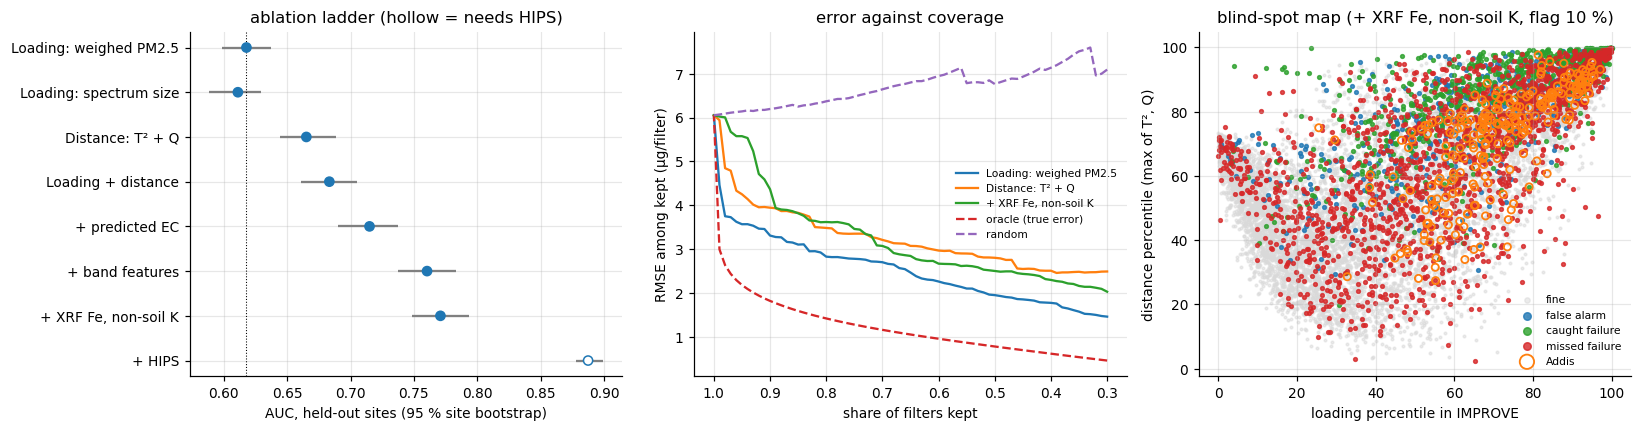

In [15]:
# the same map for SPARTAN: the best usable flag refitted on all of IMPROVE, applied to Addis and the network
cols_best = dict((label, cols) for label, cols, _ in RUNGS)[BEST]
clf_best = new_clf().fit(FI[cols_best], IMPACTED)


def spartan_features(Xmain, Xraw, meta):
    F = spectral_features(Xraw)
    F["t2"], F["q"] = ALL[MAIN].distances(Xmain, k_main)
    F["pred_ug"] = ALL[MAIN].predict(Xmain)[:, k_main - 1]
    vol = meta.volume_m3.where(meta.volume_m3 > 0).to_numpy()
    pm = meta.pm25_ugm3.to_numpy()
    F["pm_ug"] = pm * vol
    F["hips_ug"] = meta.hips_ug.to_numpy()
    F["ftir_over_hips"] = F.pred_ug / np.clip(F.hips_ug, 0.05, None)
    F["fe_frac"] = meta.fe_ugm3.to_numpy() / pm
    F["nsk_frac"] = (meta.k_xrf_ugm3.to_numpy() - 0.6 * meta.fe_ugm3.to_numpy()) / pm
    return F


# Addis is every network ETAD filter (the frozen evaluation set plus the filters sampled after it), not only the frozen set
FN = spartan_features(XN[MAIN], XN["raw"], nm)
r = clf_best.predict_proba(FN[cols_best])[:, 1]
MAP_SPARTAN = pd.DataFrame({"population": np.where(nm.code == "ETAD", "Addis", "network"), "filter_id": nm.filter_id, "code": nm.code,
                            "date": nm.date.dt.date, "season": nm.season,
                            "loading percentile": pct_of(REF_PM, FN.pm_ug), "distance percentile": dist_pct(FN.t2, FN.q),
                            "PM2.5 µg": FN.pm_ug, "risk": r, "flagged": r >= np.quantile(risk, 1 - FLAG_RATE),
                            "beyond IMPROVE loading": FN.pm_ug > np.nanmax(REF_PM)})[~nm.excluded.to_numpy()].reset_index(drop=True)
MAP_IMPROVE = pd.DataFrame({"filter_id": im.filter_id, "site": im.site, "loading percentile": im_load_pct, "distance percentile": im_dist_pct,
                            "category": CATEGORY, "error µg": ERR, "risk": risk})

# failure rate and catch rate on a 5 × 5 grid of loading × distance, with how many Addis filters fall in each cell
edges = np.linspace(0, 100, 6)
cell = lambda p: np.clip(np.digitize(p, edges[1:-1]), 0, 4)
li, di = cell(im_load_pct), cell(im_dist_pct)
a_map = MAP_SPARTAN[MAP_SPARTAN.population == "Addis"]
la, da = cell(a_map["loading percentile"].to_numpy()), cell(a_map["distance percentile"].to_numpy())
rows = []
for i in range(5):
    for j in range(5):
        m = (li == i) & (di == j) & np.isfinite(im_load_pct)
        rows.append({"loading bin": i, "distance bin": j, "loading range": f"{edges[i]:.0f}–{edges[i + 1]:.0f}",
                     "distance range": f"{edges[j]:.0f}–{edges[j + 1]:.0f}", "IMPROVE filters": int(m.sum()),
                     "impacted share": IMPACTED[m].mean() if m.any() else np.nan,
                     "caught share": (IMPACTED[m] & flagged[m]).sum() / max(IMPACTED[m].sum(), 1) if IMPACTED[m].any() else np.nan,
                     "Addis filters": int(((la == i) & (da == j) & a_map["loading percentile"].notna().to_numpy()).sum())})
GRID = pd.DataFrame(rows)
print(f"Addis: median loading percentile {a_map['loading percentile'].median():.0f}, distance percentile {a_map['distance percentile'].median():.0f}; "
      f"{a_map['beyond IMPROVE loading'].mean():.0%} heavier than any IMPROVE filter; {a_map.flagged.mean():.0%} flagged by '{BEST}'")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
L = LADDER.iloc[::-1]
ax[0].errorbar(L.AUC, range(len(L)), xerr=[L.AUC - L["AUC lo"], L["AUC hi"] - L.AUC], fmt="none", ecolor="0.5")
ax[0].scatter(L.AUC, range(len(L)), c=np.where(L["at SPARTAN"], "tab:blue", "white"), edgecolors="tab:blue", zorder=3)
ax[0].set(yticks=range(len(L)), yticklabels=L.rung, xlabel="AUC, held-out sites (95 % site bootstrap)", title="ablation ladder (hollow = needs HIPS)")
ax[0].axvline(LADDER.AUC.iloc[0], color="k", lw=.7, ls=":")
for label in [RUNGS[0][0], "Distance: T² + Q", BEST, "oracle (true error)", "random"]:
    d = COVERAGE[COVERAGE.score == label]
    ax[1].plot(d["kept share"], d["RMSE kept"], label=label, ls="--" if label in ("oracle (true error)", "random") else "-")
ax[1].set(xlabel="share of filters kept", ylabel="RMSE among kept (µg/filter)", title="error against coverage"); ax[1].invert_xaxis(); ax[1].legend(frameon=False, fontsize=7)
colors = {"fine": "0.85", "false alarm": "tab:blue", "caught failure": "tab:green", "missed failure": "tab:red"}
for cat, c in colors.items():
    m = CATEGORY == cat
    ax[2].scatter(im_load_pct[m], im_dist_pct[m], s=3 if cat == "fine" else 6, c=c, alpha=.5 if cat == "fine" else .8, label=cat)
ax[2].scatter(a_map["loading percentile"], a_map["distance percentile"], s=22, facecolors="none", edgecolors="tab:orange", lw=1.2, label="Addis")
ax[2].set(xlabel="loading percentile in IMPROVE", ylabel="distance percentile (max of T², Q)", title=f"blind-spot map ({BEST}, flag 10 %)")
ax[2].legend(frameon=False, fontsize=7, markerscale=2)
plt.tight_layout(); plt.show()

**How to read it.** If *Distance: T² + Q* sits at loading's AUC, or its within-decile AUCs hover near 0.5,
the distance is mostly a scale and the standard "outside the calibration domain" test adds little for EC. A rung is
worth keeping only if its gain interval clears zero. On the coverage panel, a useful flag bends its curve toward the
oracle; a curve that tracks random only discards data. In the map, missed failures (red) are what a spectrum-based
flag cannot see: if Addis (orange rings) sits where red points cluster and green ones do not, a spectral warning
will stay quiet at Addis however good its AUC is, and only reference filters can settle it.

## 7. Option A: is there one model that is better on the hard filters without being worse elsewhere?

From the out-of-site predictions of Section 2: for each preprocessing and each k, the error on the hard IMPROVE groups
(union of the five) against the error on the rest. Then the Addis readout of the same models (fitted on all IMPROVE):
predicted FTIR EC against HIPS BC, Deming slope and intercept by k, beside SPARTAN's published EC.

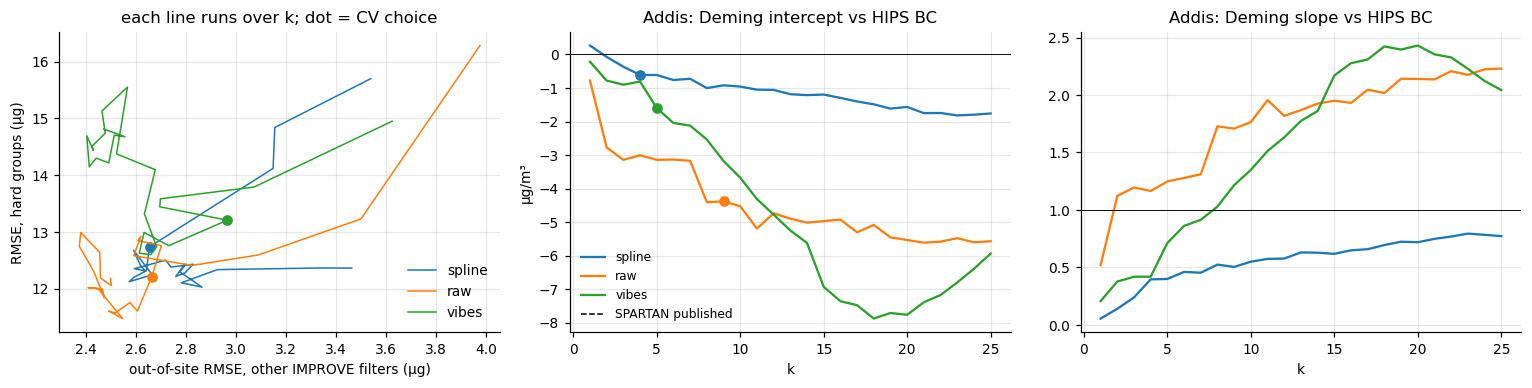

CV choice of k                                                      best k for the hard groups                                                     
                           k RMSE all RMSE hard groups RMSE rest bias hard groups                          k RMSE all RMSE hard groups RMSE rest bias hard groups
preprocessing                                                                                                                                                    
spline                     4    6.055           12.737     2.655           -2.497                         21    5.852           12.027     2.865           -0.773
raw                        9    5.843           12.199     2.663           -1.471                         14    5.511           11.473     2.547           -0.855
vibes                      5    6.356           13.205     2.966           -1.901                          9    6.001           12.598     2.660           -1.151

In [16]:
HARD = np.any([G[g] for g in GROUP_DEF], axis=0)
rows = []
for prep in PREPS_ALL:
    for k in range(1, K_MAX + 1):
        e = OOF[prep][:, k - 1] - y
        rows.append({"preprocessing": prep, "k": k, "RMSE all": rmse(e), "RMSE hard groups": rmse(e[HARD]),
                     "RMSE rest": rmse(e[~HARD]), "bias hard groups": e[HARD].mean()})
TRADE = pd.DataFrame(rows)

for prep in PREPS_ALL:
    if prep not in ALL:
        ALL[prep] = PLS().fit(XI[prep], y)
xa, vol = am.hips_bc.to_numpy()[ADDIS], am.volume_m3.to_numpy()[ADDIS]
rows = []
for prep in PREPS_ALL:
    P = ALL[prep].predict(XA[prep][ADDIS]) / vol[:, None]
    for k in range(1, ALL[prep].K + 1):
        s, i = deming(xa, P[:, k - 1], LAMBDA_ADDIS)
        rows.append({"preprocessing": prep, "k": k, "Addis slope": s, "Addis intercept": i})
ADDIS_K = pd.DataFrame(rows)
pub_s, pub_i = deming(xa, am.ec_published_ugm3.to_numpy()[ADDIS], LAMBDA_ADDIS)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for prep in PREPS_ALL:
    d = TRADE[TRADE.preprocessing == prep]
    ax[0].plot(d["RMSE rest"], d["RMSE hard groups"], "-", lw=1, label=prep)
    c = ax[0].lines[-1].get_color()
    kk = d[d.k == KSEL[prep]]
    ax[0].plot(kk["RMSE rest"], kk["RMSE hard groups"], "o", color=c)
    a = ADDIS_K[ADDIS_K.preprocessing == prep]
    ax[1].plot(a.k, a["Addis intercept"], color=c, label=prep); ax[2].plot(a.k, a["Addis slope"], color=c)
    ax[1].plot(KSEL[prep], a["Addis intercept"].iloc[KSEL[prep] - 1], "o", color=c)
ax[0].set(xlabel="out-of-site RMSE, other IMPROVE filters (µg)", ylabel="RMSE, hard groups (µg)", title="each line runs over k; dot = CV choice")
ax[1].axhline(pub_i, color="k", ls="--", lw=1, label="SPARTAN published"); ax[1].axhline(0, color="k", lw=.6)
ax[1].set(xlabel="k", ylabel="µg/m³", title="Addis: Deming intercept vs HIPS BC")
ax[2].axhline(pub_s, color="k", ls="--", lw=1); ax[2].axhline(1, color="k", lw=.6)
ax[2].set(xlabel="k", title="Addis: Deming slope vs HIPS BC")
ax[0].legend(frameon=False); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
best = TRADE.loc[TRADE.groupby("preprocessing")["RMSE hard groups"].idxmin()]
chosen = TRADE.merge(pd.DataFrame({"preprocessing": list(KSEL), "k": list(KSEL.values())}))
display(pd.concat({"CV choice of k": chosen.set_index("preprocessing"), "best k for the hard groups": best.set_index("preprocessing")}, axis=1))

**How to read it.** A single better model would show as a point below and not right of the CV choice in the left
panel (better on the hard groups, no worse on the rest). The middle panel is the known "Addis intercept follows k"
pattern: if IMPROVE error barely changes with k while the Addis intercept keeps moving, IMPROVE cannot choose k for
Addis, and A cannot be settled without an Addis reference.

## 7b. The local calibration outside IMPROVE: Addis and the network

Section 4 found that a **local** calibration (each filter calibrated on its own `N_SELECT` most similar IMPROVE
spectra) beats the full calibration set on held-out IMPROVE sites, hard and ordinary filters alike. Here it is applied,
on raw spectra with the raw CV choice of k, to every Addis filter and every SPARTAN PM2.5 filter, and read out against
HIPS BC beside the full raw model and SPARTAN's published EC. The **neighbour similarity** (median correlation of a
filter's spline spectrum with its 500 neighbours') and **heavier than neighbours** (its HIPS loading ÷ theirs) say how
close IMPROVE comes to it; IMPROVE filters' own values (neighbours from other sites) are the yardstick. HIPS is a cross-check here, not the truth.

local predictions for 3,750 SPARTAN filters in 92 s
neighbour similarity (spline spectra), median: IMPROVE filters (neighbours at other sites) 0.979, Addis 0.933, network 0.964
HIPS loading ÷ neighbours' median, median: IMPROVE 1.0, Addis 3.6, network 2.3


**Addis, against HIPS BC (Deming, Addis error ratio)**

,season,n,neighbour similarity,heavier than neighbours (×),local raw slope,local raw intercept,local raw ÷ HIPS (median),full raw slope,full raw intercept,full raw ÷ HIPS (median),published slope,published intercept,published ÷ HIPS (median)
0,All Addis,233,0.933,3.585,2.800,-7.864,1.069,1.708,-4.382,0.715,2.297,-6.088,0.986
1,Belg (Mar-May),60,0.917,3.583,2.542,-6.448,1.130,1.482,-3.328,0.727,1.886,-4.170,0.983
2,Dry (Oct-Feb),102,0.947,3.944,1.764,-3.809,0.829,0.892,-1.157,0.594,1.412,-2.620,0.777
3,Kiremt (Jun-Sep),71,0.927,3.278,2.733,-7.094,1.493,1.758,-4.254,1.015,2.189,-5.095,1.286


**SPARTAN sites, least similar to IMPROVE first**

,code,n,neighbour similarity,heavier than neighbours (×),local raw slope,local raw intercept,local raw ÷ HIPS (median),full raw slope,full raw intercept,full raw ÷ HIPS (median),published slope,published intercept,published ÷ HIPS (median),site
2,BDDU,46,0.903,3.934,1.467,-2.645,0.791,0.973,-1.179,0.656,1.138,-1.599,0.685,"Dhaka, Bangladesh"
8,CLTA,84,0.916,3.961,1.345,-0.652,0.577,1.206,-0.448,0.633,1.634,-1.075,0.509,"Talca, Chile"
20,PRFJ,72,0.932,0.482,0.867,-0.020,0.460,14.621,-1.393,0.557,1.217,0.048,1.750,"Fajardo, PuertoRico"
9,ETAD,232,0.934,3.588,2.787,-7.808,1.067,1.703,-4.365,0.713,2.216,-5.790,0.910,"Addis Ababa, Ethiopia"
3,BIBU,53,0.938,2.932,1.813,-3.054,0.937,1.196,-1.575,0.783,1.729,-2.597,0.988,"Bujumbura, Burundi"
19,NGIL,0,0.938,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Ilorin, Nigeria"
1,AUMN,75,0.943,3.197,0.885,-0.083,0.709,0.556,0.040,0.583,0.638,0.043,0.735,"Melbourne, Australia"
4,CAHA,50,0.948,1.527,0.682,0.094,1.097,0.738,0.039,0.910,1.074,-0.004,0.885,"Halifax, Canada"
5,CASH,47,0.953,1.489,1.111,0.002,1.174,5.222,-1.039,0.894,6.305,-1.454,1.099,"Sherbrooke, Canada"
7,CLST,167,0.954,3.454,1.975,-2.153,0.785,1.294,-1.321,0.522,1.411,-1.273,0.666,"Santiago, Chile"


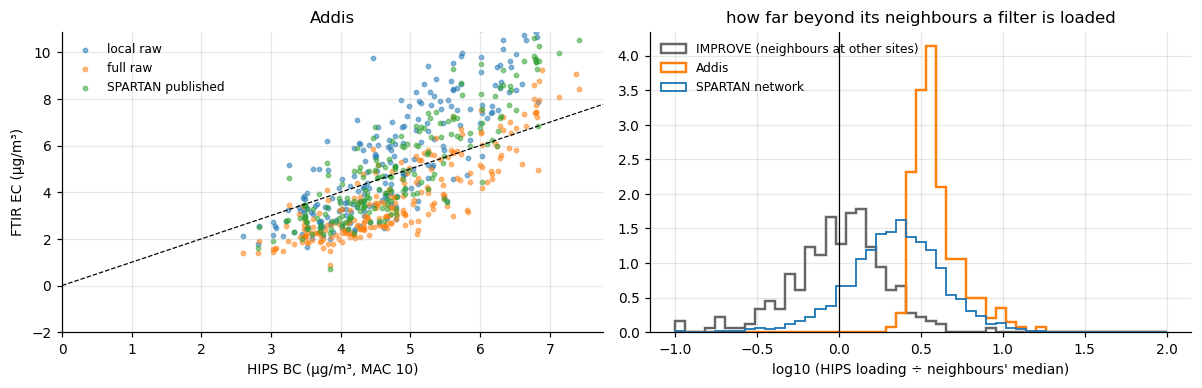

In [17]:
LOCAL_PREP = "raw"
k_loc = KSEL[LOCAL_PREP]
mask_loc = corr_mask(LOCAL_PREP)
Z_lib = unit_rows(XI[LOCAL_PREP], mask_loc)
ZS_lib = unit_rows(XI["spline"], corr_mask("spline"))   # raw spectra all correlate ~0.998 (filter and baseline): judge closeness on spline
HIPS_lib = im.hips_ug.to_numpy()


def local_predict(Xt, Xt_spline, hips_t, exclude_site=None, chunk=400):
    """Each target filter: PLS on its N_SELECT most correlated IMPROVE raw spectra (all of IMPROVE, or other sites only).
    Also returns how close the neighbours are (median correlation of the spline spectra) and how much heavier the
    target is than its neighbours (HIPS µg per filter ÷ the neighbours' median)."""
    Zt, Zts = unit_rows(Xt, mask_loc), unit_rows(Xt_spline, corr_mask("spline"))
    pred, sim, heavier = np.empty(len(Xt)), np.empty(len(Xt)), np.empty(len(Xt))
    for a in range(0, len(Xt), chunk):
        C = Zt[a:a + chunk] @ Z_lib.T
        for j, row in enumerate(C):
            i = a + j
            if exclude_site is not None:
                row = np.where(sites == exclude_site[i], -np.inf, row)
            nn = np.argpartition(-row, N_SELECT)[:N_SELECT]
            pred[i] = PLS(k_loc).fit(XI[LOCAL_PREP][nn], y[nn]).predict(Xt[i:i + 1])[0, k_loc - 1]
            sim[i] = np.median(ZS_lib[nn] @ Zts[i])
            heavier[i] = hips_t[i] / np.median(HIPS_lib[nn])
    return pred, sim, heavier


t0 = time.time()
rng = np.random.default_rng(SEED + 2)
ref_rows = rng.choice(len(y), 300, replace=False)
_, sim_I, heavy_I = local_predict(XI[LOCAL_PREP][ref_rows], XI["spline"][ref_rows], HIPS_lib[ref_rows], exclude_site=sites[ref_rows])
loc_a, sim_a, heavy_a = local_predict(XA[LOCAL_PREP], XA["spline"], am.hips_ug.to_numpy())
loc_n, sim_n, heavy_n = local_predict(XN[LOCAL_PREP], XN["spline"], nm.hips_ug.to_numpy())
vol_a, vol_n = am.volume_m3.where(am.volume_m3 > 0).to_numpy(), nm.volume_m3.where(nm.volume_m3 > 0).to_numpy()
add["ec_local"], add["ec_full_raw"] = loc_a / vol_a, ALL[LOCAL_PREP].predict(XA[LOCAL_PREP])[:, k_loc - 1] / vol_a
add["neighbour_similarity"], add["heavier_than_neighbours"] = sim_a, heavy_a
per_filter = pd.DataFrame({"ec_local": loc_n / vol_n, "ec_full_raw": ALL[LOCAL_PREP].predict(XN[LOCAL_PREP])[:, k_loc - 1] / vol_n,
                           "neighbour_similarity": sim_n, "heavier_than_neighbours": heavy_n}, index=nm.index)
net = net.drop(columns=[c for c in per_filter if c in net]).join(per_filter)
print(f"local predictions for {len(add) + len(nm):,} SPARTAN filters in {time.time() - t0:.0f} s")
print(f"neighbour similarity (spline spectra), median: IMPROVE filters (neighbours at other sites) {np.median(sim_I):.3f}, "
      f"Addis {np.median(sim_a[ADDIS]):.3f}, network {np.nanmedian(sim_n):.3f}")
print(f"HIPS loading ÷ neighbours' median, median: IMPROVE {np.nanmedian(heavy_I):.1f}, Addis {np.nanmedian(heavy_a[ADDIS]):.1f}, "
      f"network {np.nanmedian(heavy_n):.1f}")


def readout(d, by):
    rows = []
    for key, g in d.groupby(by):
        ok = g.hips_bc.notna() & (g.hips_bc > 0)
        row = dict(zip(by, key if isinstance(key, tuple) else (key,)))
        row.update({"n": int(ok.sum()), "neighbour similarity": g.neighbour_similarity.median(),
                    "heavier than neighbours (×)": g.heavier_than_neighbours.median()})
        for name, col in (("local raw", "ec_local"), ("full raw", "ec_full_raw"), ("published", "ec_ftir_ugm3")):
            m = ok & g[col].notna()
            if m.sum() >= 15:
                s_, i_ = deming(g.hips_bc[m], g[col][m], LAMBDA_ADDIS)
                row.update({f"{name} slope": s_, f"{name} intercept": i_, f"{name} ÷ HIPS (median)": (g[col] / g.hips_bc)[m].median()})
        rows.append(row)
    return pd.DataFrame(rows)


LOCAL_ADDIS = readout(add[ADDIS].assign(all="All Addis"), ["all"])
LOCAL_ADDIS = pd.concat([LOCAL_ADDIS.rename(columns={"all": "season"}), readout(add[ADDIS], ["season"])], ignore_index=True)
LOCAL_SITES = readout(net, ["code"]).assign(site=lambda d: d.code.map(SITE_NAME)).sort_values("neighbour similarity")
display(Markdown("**Addis, against HIPS BC (Deming, Addis error ratio)**")); display(LOCAL_ADDIS)
display(Markdown("**SPARTAN sites, least similar to IMPROVE first**")); display(LOCAL_SITES)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
a = add[ADDIS]
lim = np.nanpercentile(a.hips_bc, 99) * 1.1
for col, lab in (("ec_local", "local raw"), ("ec_full_raw", "full raw"), ("ec_ftir_ugm3", "SPARTAN published")):
    ax[0].scatter(a.hips_bc, a[col], s=8, alpha=.5, label=lab)
ax[0].plot([0, lim], [0, lim], "k--", lw=.8)
ax[0].set(xlim=(0, lim), ylim=(min(-2, np.nanmin(a.ec_local)), lim * 1.4), xlabel="HIPS BC (µg/m³, MAC 10)", ylabel="FTIR EC (µg/m³)", title="Addis")
ax[0].legend(frameon=False, fontsize=8)
bins = np.linspace(-1, 2, 50)
for v, lab, kw in ((heavy_I, "IMPROVE (neighbours at other sites)", {"color": "0.4", "lw": 1.6}), (heavy_a[ADDIS], "Addis", {"color": "tab:orange", "lw": 1.6}),
                   (heavy_n, "SPARTAN network", {"lw": 1.2})):
    v = v[np.isfinite(v) & (v > 0)]
    ax[1].hist(np.log10(v), bins, histtype="step", density=True, label=lab, **kw)
ax[1].axvline(0, color="k", lw=.8)
ax[1].set(xlabel="log10 (HIPS loading ÷ neighbours' median)", title="how far beyond its neighbours a filter is loaded"); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**How to read it.** If the local calibration brings Addis toward the HIPS line (slope near 1, intercept near 0) while
staying close to the published values at sites where FTIR and HIPS already agree, it is a strong candidate to freeze
before the Addis TOR filters arrive. If it moves Addis *further* from HIPS, the gain inside IMPROVE does not carry over,
and the reason is likely in the last column: a filter several times heavier than all of its neighbours is extrapolated
in loading, however similar its spectral shape.

## 8. Decision board

The board is filled from this run. Read the "suggests" column as a statement about *this* data and these settings; the
tables above carry the uncertainty. The last cell writes down, before the Addis TOR filters arrive, what agreement would
count as evidence (option D). Edit it, then keep the saved file as the record.

In [18]:
def verdict_b(d):
    if d.empty:
        return "not testable here"
    b = d.sort_values("RMSE change vs full, % (median)").iloc[0]
    if b["wins (share of splits)"] >= 0.8 and b["RMSE change vs full, % (median)"] <= -10:
        return f"helps: {b.rule} ({b['RMSE change vs full, % (median)']:+.0f} %, wins {b['wins (share of splits)']:.0%})"
    if b["wins (share of splits)"] <= 0.3:
        return f"does not help (best: {b.rule}, {b['RMSE change vs full, % (median)']:+.0f} %)"
    return f"mixed (best: {b.rule}, {b['RMSE change vs full, % (median)']:+.0f} %, wins {b['wins (share of splits)']:.0%})"

rows = []
c = chosen.set_index("preprocessing").loc[MAIN]
ok = TRADE[TRADE["RMSE rest"] <= 1.05 * c["RMSE rest"]]
b = ok.loc[ok["RMSE hard groups"].idxmin()]
ai = ADDIS_K.set_index(["preprocessing", "k"])["Addis intercept"]
rows.append({"option": "A. one better model", "test": f"best (preprocessing, k) on the hard groups, no worse than +5 % on the rest, vs {MAIN} k = {int(c.k)}",
             "result": f"{b.preprocessing} k {int(b.k)}: hard {b['RMSE hard groups']:.2f} vs {c['RMSE hard groups']:.2f} µg, rest {b['RMSE rest']:.2f} vs {c['RMSE rest']:.2f}; "
                       f"Addis intercept {ai[(b.preprocessing, int(b.k))]:+.2f} vs {ai[(MAIN, int(c.k))]:+.2f} µg/m³",
             "suggests": "better on IMPROVE's hard filters; Addis readout moves with it, so it cannot be judged at Addis without a reference"
                         if b["RMSE hard groups"] < 0.95 * c["RMSE hard groups"] else "no single model is clearly better on the hard groups"})
ON_SPARTAN = {"same kind": {"Heavy loading": "yes (HIPS)", "Low OC/BC": "needs FTIR OC", "Smoke (non-soil K)": "needs XRF K and Fe",
                            "Urban sites": "yes (site)", "Addis-like spectra": "yes (spectrum)"},
              "target analogs": "yes (spectrum)", "local": "yes (spectrum)"}
for g in GROUPS_PLUS:
    d = SPEC[SPEC.group == g]
    if d.empty:
        continue
    bb = d.sort_values("RMSE change vs full, % (median)").iloc[0]
    avail = ON_SPARTAN[bb.rule] if isinstance(ON_SPARTAN[bb.rule], str) else ON_SPARTAN[bb.rule][g]
    rows.append({"option": "B. specialists + rule", "test": f"{g}: best rule over {', '.join(PREPS)}",
                 "result": f"{bb.preprocessing} · {bb.rule}: {bb['RMSE change vs full, % (median)']:+.0f} %, wins {bb['wins (share of splits)']:.0%}; usable on SPARTAN: {avail}",
                 "suggests": verdict_b(d)})
fl = FLAGS.set_index("flag")
used = "spectrum + HIPS" if FLAG_COLS is WITH_HIPS else "spectrum only"
best_single = fl.drop(index=["spectrum only", "spectrum + HIPS"]).AUC.idxmax()
rows.append({"option": "C. flag", "test": f"held-out-site AUC ({used}) vs the best single quantity",
             "result": f"{fl.AUC[used]:.2f} vs {fl.AUC[best_single]:.2f} ({best_single})",
             "suggests": "the flag adds information" if fl.AUC[used] >= fl.AUC[best_single] + 0.03 else "a single quantity does as well"})
top = SITES.head(5)
rows.append({"option": "C. flag", "test": "sites with the highest mean flag",
             "result": ", ".join(f"{r.code} {r['mean flag (+ HIPS)']:.2f}" for _, r in top.iterrows()),
             "suggests": f"Addis: {add.flag_hips[ADDIS].mean():.2f} (+ HIPS) and {add.flag_spectrum[ADDIS].mean():.2f} (spectrum only) mean flag, "
                         f"{add.outside_range[ADDIS].mean():.0%} outside the IMPROVE range"})
la = LOCAL_ADDIS.set_index("season").loc["All Addis"]
rows.append({"option": "A'. local calibration (raw)", "test": "Addis against HIPS BC: local vs full raw vs published (Deming)",
             "result": f"local {la['local raw slope']:.2f}x {la['local raw intercept']:+.2f}; full raw {la['full raw slope']:.2f}x {la['full raw intercept']:+.2f}; "
                       f"published {la['published slope']:.2f}x {la['published intercept']:+.2f}; neighbour similarity {la['neighbour similarity']:.3f} vs IMPROVE {np.median(sim_I):.3f}",
             "suggests": "moves Addis further from HIPS than the published EC: the IMPROVE gain does not carry over"
                         if abs(la["local raw intercept"]) > abs(la["published intercept"]) else
                         "moves Addis toward HIPS: a candidate to freeze for the Addis TOR test (HIPS is only a cross-check)"})
rows.append({"option": "D. new references", "test": "see the next cell", "result": "", "suggests": "write the pass criteria before the filters arrive"})
BOARD = pd.DataFrame(rows)
display(BOARD)

,option,test,result,suggests
0,A. one better model,"best (preprocessing, k) on the hard groups, no...","raw k 14: hard 11.47 vs 12.74 µg, rest 2.55 vs...",better on IMPROVE's hard filters; Addis readou...
1,B. specialists + rule,"Heavy loading: best rule over spline, raw","raw · local: -31 %, wins 90%; usable on SPARTA...","helps: local (-31 %, wins 90%)"
2,B. specialists + rule,"Low OC/BC: best rule over spline, raw","raw · local: -41 %, wins 100%; usable on SPART...","helps: local (-41 %, wins 100%)"
3,B. specialists + rule,"Smoke (non-soil K): best rule over spline, raw","raw · local: -25 %, wins 70%; usable on SPARTA...","mixed (best: local, -25 %, wins 70%)"
4,B. specialists + rule,"Urban sites: best rule over spline, raw","raw · local: -40 %, wins 100%; usable on SPART...","helps: local (-40 %, wins 100%)"
5,B. specialists + rule,"Addis-like spectra: best rule over spline, raw","raw · local: -46 %, wins 90%; usable on SPARTA...","helps: local (-46 %, wins 90%)"
6,B. specialists + rule,"None of these: best rule over spline, raw","raw · local: -23 %, wins 90%; usable on SPARTA...","helps: local (-23 %, wins 90%)"
7,C. flag,held-out-site AUC (spectrum + HIPS) vs the bes...,0.89 vs 0.68 (q alone),the flag adds information
8,C. flag,sites with the highest mean flag,"ETAD 0.79, BDDU 0.59, INJA 0.40, ZAJB 0.36, CL...",Addis: 0.85 (+ HIPS) and 0.26 (spectrum only) ...
9,A'. local calibration (raw),Addis against HIPS BC: local vs full raw vs pu...,local 2.80x -7.86; full raw 1.71x -4.38; publi...,moves Addis further from HIPS than the publish...


In [19]:
# Option D: what the Addis TOR filters must show, written before they arrive (edit, then save)
PREDECLARED = {
    "written": time.strftime("%Y-%m-%d"),
    "candidate models (frozen before the filters are read)": [
        f"full IMPROVE calibration set, {MAIN}, k = {KSEL[MAIN]}",
        f"full IMPROVE calibration set, raw (SPARTAN-like), k = {KSEL.get('raw')}",
        f"local calibration: each filter's {N_SELECT} most similar IMPROVE raw spectra, k = {KSEL.get('raw')} (Section 7b)",
        "SPARTAN published EC (deployed model)",
    ],
    "reference": "TOR EC on collocated quartz filters, same sampling days",
    "metrics": ["mean bias (µg/m³ and % of TOR)", "Deming slope and intercept against TOR", "RMSE"],
    "pass if": {"abs(mean bias) <= % of TOR": 20, "slope within": [0.8, 1.2], "abs(intercept) <= µg/m³": 0.5},
    "also report": ["the flag and the outside-range mark for each filter", "whether the filters resemble the SPARTAN Addis filters (loading per filter, OC/BC, Addis-like spectra)"],
    "caveat": "about 10 filters, from a different site and sampler: a check, not a calibration",
}
print(json.dumps(PREDECLARED, indent=2, ensure_ascii=False))

{
  "written": "2026-10-26",
  "candidate models (frozen before the filters are read)": [
    "full IMPROVE calibration set, spline, k = 4",
    "full IMPROVE calibration set, raw (SPARTAN-like), k = 9",
    "local calibration: each filter's 500 most similar IMPROVE raw spectra, k = 9 (Section 7b)",
    "SPARTAN published EC (deployed model)"
  ],
  "reference": "TOR EC on collocated quartz filters, same sampling days",
  "metrics": [
    "mean bias (µg/m³ and % of TOR)",
    "Deming slope and intercept against TOR",
    "RMSE"
  ],
  "pass if": {
    "abs(mean bias) <= % of TOR": 20,
    "slope within": [
      0.8,
      1.2
    ],
    "abs(intercept) <= µg/m³": 0.5
  },
  "also report": [
    "the flag and the outside-range mark for each filter",
    "whether the filters resemble the SPARTAN Addis filters (loading per filter, OC/BC, Addis-like spectra)"
  ],
  "caveat": "about 10 filters, from a different site and sampler: a check, not a calibration"
}


In [20]:
# Save every table of this run next to the data
for name, df in {"section3_groups": FAIL, "section4_splits": RUNS, "section4_summary": SPEC, "section5_flag_scores": FLAGS,
                 "section6_sites": SITES, "section6_site_seasons": SITE_SEASONS, "section6_addis_seasons": ADDIS_SEASONS,
                 "section6_network_filters": net[["filter_id", "code", "date", "season", "flag_spectrum", "flag_hips", "outside_range", "ec_this_model", "ec_local", "ec_full_raw", "ec_ftir_ugm3", "hips_bc", "neighbour_similarity", "heavier_than_neighbours"]],
                 "section7_tradeoff": TRADE, "section7_addis_by_k": ADDIS_K, "section7b_local_addis": LOCAL_ADDIS, "section7b_local_sites": LOCAL_SITES,
                 "section7b_addis_filters": add[["filter_id", "date", "season", "hips_bc", "ec_local", "ec_full_raw", "ec_ftir_ugm3", "neighbour_similarity", "heavier_than_neighbours", "flag_spectrum", "flag_hips", "outside_range"]], "section8_board": BOARD,
                 "section6b_ladder": LADDER, "section6b_within_loading": WITHIN, "section6b_coverage": COVERAGE, "section6b_site_keep": SITE_KEEP,
                 "section6b_missed_summary": MISSED_SUMMARY, "section6b_missed_top": MISSED_TOP, "section6b_map_improve": MAP_IMPROVE,
                 "section6b_map_spartan": MAP_SPARTAN, "section6b_grid": GRID}.items():
    df.to_csv(RESULTS / f"{name}.csv", index=False)
settings = {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, list)) and k not in ("RESULTS",)}
(RESULTS / "settings.json").write_text(json.dumps({**settings, "k_selected": KSEL, "bundle": MANIFEST["created"]}, indent=2, default=str))
(RESULTS / "predeclared_addis_tor.json").write_text(json.dumps(PREDECLARED, indent=2, ensure_ascii=False))
print(f"saved {len(list(RESULTS.iterdir()))} files to {RESULTS}")

saved 25 files to /Users/ahmadjalil/Library/CloudStorage/GoogleDrive-ahzs645@gmail.com/My Drive/Aethmodular VIBES/decision_workbook_20261022/results/20261026-1442
